In [103]:
# Cell 1: Import Libraries and Load Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Load dataset
df = pd.read_csv('/content/GoogleAds_DataAnalytics_Sales_Uncleaned.csv')

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!
Shape of dataset: (2600, 13)


In [104]:
# Cell 2: Basic Dataset Inspection

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

Number of Rows: 2600
Number of Columns: 13

Column Names:
['Ad_ID', 'Campaign_Name', 'Clicks', 'Impressions', 'Cost', 'Leads', 'Conversions', 'Conversion Rate', 'Sale_Amount', 'Ad_Date', 'Location', 'Device', 'Keyword']

Data Types:
Ad_ID               object
Campaign_Name       object
Clicks             float64
Impressions        float64
Cost                object
Leads              float64
Conversions        float64
Conversion Rate    float64
Sale_Amount         object
Ad_Date             object
Location            object
Device              object
Keyword             object
dtype: object

First 5 Rows:


,Ad_ID,Campaign_Name,Clicks,Impressions,Cost,Leads,Conversions,Conversion Rate,Sale_Amount,Ad_Date,Location,Device,Keyword
0,A1000,DataAnalyticsCourse,104.0,4498.0,$231.88,14.0,7.0,0.058,$1892,2024-11-16,hyderabad,desktop,learn data analytics
1,A1001,DataAnalyticsCourse,173.0,5107.0,$216.84,10.0,8.0,0.046,$1679,20-11-2024,hyderabad,mobile,data analytics course
2,A1002,Data Anlytics Corse,90.0,4544.0,$203.66,26.0,9.0,NaN,$1624,2024/11/16,hyderabad,Desktop,data analitics online
3,A1003,Data Analytcis Course,142.0,3185.0,$237.66,17.0,6.0,NaN,$1225,2024-11-26,HYDERABAD,tablet,data anaytics training
4,A1004,Data Analytics Corse,156.0,3361.0,$195.9,30.0,8.0,NaN,$1091,2024-11-22,hyderabad,desktop,online data analytic



Last 5 Rows:


,Ad_ID,Campaign_Name,Clicks,Impressions,Cost,Leads,Conversions,Conversion Rate,Sale_Amount,Ad_Date,Location,Device,Keyword
2595,A3595,DataAnalyticsCourse,88.0,5344.0,$242.07,17.0,9.0,0.054,$1418,29-11-2024,HYDERABAD,MOBILE,online data analytic
2596,A3596,DataAnalyticsCourse,154.0,3211.0,$248.28,14.0,6.0,0.039,$1950,2024/11/28,hyderabad,TABLET,data analitics online
2597,A3597,Data Anlytics Corse,113.0,3808.0,$233.25,18.0,4.0,0.035,$1085,2024-11-02,Hyderbad,desktop,data anaytics training
2598,A3598,Data Analytics Corse,196.0,5853.0,$220.13,16.0,7.0,0.036,$1558,2024-11-08,hydrebad,Tablet,data anaytics training
2599,A3599,Data Analytics Corse,NaN,5453.0,NaN,12.0,5.0,NaN,$1174,2024/11/22,HYDERABAD,desktop,analytics for data


In [105]:
# Cell 3: Dataset Information

print("Dataset Information:\n")
df.info()

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2600 entries, 0 to 2599
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Ad_ID            2600 non-null   object 
 1   Campaign_Name    2600 non-null   object 
 2   Clicks           2488 non-null   float64
 3   Impressions      2546 non-null   float64
 4   Cost             2503 non-null   object 
 5   Leads            2552 non-null   float64
 6   Conversions      2526 non-null   float64
 7   Conversion Rate  1974 non-null   float64
 8   Sale_Amount      2461 non-null   object 
 9   Ad_Date          2600 non-null   object 
 10  Location         2600 non-null   object 
 11  Device           2600 non-null   object 
 12  Keyword          2600 non-null   object 
dtypes: float64(5), object(8)
memory usage: 264.2+ KB


In [106]:
# Cell 4: Check Missing Values

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Column': df.columns,
    'Missing_Values': missing_values.values,
    'Missing_Percentage': (missing_values.values / len(df)) * 100
})

missing_summary = missing_summary.sort_values(
    by='Missing_Values',
    ascending=False
)

display(missing_summary)

,Column,Missing_Values,Missing_Percentage
7,Conversion Rate,626,24.076923
8,Sale_Amount,139,5.346154
2,Clicks,112,4.307692
4,Cost,97,3.730769
6,Conversions,74,2.846154
3,Impressions,54,2.076923
5,Leads,48,1.846154
1,Campaign_Name,0,0.000000
0,Ad_ID,0,0.000000
9,Ad_Date,0,0.000000


In [107]:
# Cell 5: Check Duplicate Records

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

if duplicate_count == 0:
    print("No duplicate rows found.")
else:
    print("Duplicate rows found. Further investigation is required.")

Number of duplicate rows: 0
No duplicate rows found.


In [108]:
# Cell 6: Numerical Column Summary

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Clicks,2488.0,138.956994,34.619376,80.000,110.000,139.000,169.000,199.000
Impressions,2546.0,4523.280833,869.927913,3000.000,3764.000,4518.500,5279.500,5999.000
Leads,2552.0,20.003918,6.032317,10.000,15.000,20.000,25.000,30.000
Conversions,2526.0,6.519002,2.272573,3.000,5.000,7.000,9.000,10.000
Conversion Rate,1974.0,0.048979,0.019987,0.015,0.035,0.046,0.058,0.123


In [109]:
# Cell 7: Check Categorical Variables

categorical_columns = [
    'Campaign_Name',
    'Location',
    'Device',
    'Keyword'
]

for column in categorical_columns:
    print("\n" + "="*60)
    print(f"Column: {column}")
    print("Number of unique values:", df[column].nunique())
    print("Unique values:")
    print(df[column].unique())


Column: Campaign_Name
Number of unique values: 4
Unique values:
['DataAnalyticsCourse' 'Data Anlytics Corse' 'Data Analytcis Course'
 'Data Analytics Corse']

Column: Location
Number of unique values: 4
Unique values:
['hyderabad' 'HYDERABAD' 'Hyderbad' 'hydrebad']

Column: Device
Number of unique values: 9
Unique values:
['desktop' 'mobile' 'Desktop' 'tablet' 'MOBILE' 'TABLET' 'Tablet' 'Mobile'
 'DESKTOP']

Column: Keyword
Number of unique values: 6
Unique values:
['learn data analytics' 'data analytics course' 'data analitics online'
 'data anaytics training' 'online data analytic' 'analytics for data']


In [110]:
# Cell 8: Frequency Distribution of Categorical Columns

for column in categorical_columns:
    print("\n" + "="*60)
    print(f"Value Counts for: {column}")
    display(df[column].value_counts(dropna=False))


Value Counts for: Campaign_Name


,count
Campaign_Name,
Data Analytcis Course,680
Data Analytics Corse,647
DataAnalyticsCourse,637
Data Anlytics Corse,636



Value Counts for: Location


,count
Location,
HYDERABAD,661
Hyderbad,656
hyderabad,650
hydrebad,633



Value Counts for: Device


,count
Device,
MOBILE,311
desktop,305
Desktop,305
tablet,305
Mobile,291
TABLET,279
DESKTOP,278
mobile,276
Tablet,250



Value Counts for: Keyword


,count
Keyword,
online data analytic,453
learn data analytics,444
data analytics course,440
analytics for data,429
data analitics online,420
data anaytics training,414


In [111]:
# Cell 9: Inspect Advertisement Dates

print("Sample date values:")
display(df['Ad_Date'].head(20))

print("\nNumber of unique date formats/values:")
print(df['Ad_Date'].nunique())

Sample date values:


,Ad_Date
0,2024-11-16
1,20-11-2024
2,2024/11/16
3,2024-11-26
4,2024-11-22
5,16-11-2024
6,06-11-2024
7,2024/11/24
8,2024/11/24
9,2024/11/12



Number of unique date formats/values:
90


In [112]:
# Cell 10: Inspect Numeric Variables Safely

numeric_columns = [
    'Clicks',
    'Impressions',
    'Cost',
    'Leads',
    'Conversions',
    'Conversion Rate',
    'Sale_Amount'
]

for column in numeric_columns:
    print("\n" + "="*60)
    print(f"Column: {column}")
    print("Data type:", df[column].dtype)
    print("Missing:", df[column].isnull().sum())

    # Check whether the column is numeric
    if pd.api.types.is_numeric_dtype(df[column]):
        print("Minimum:", df[column].min())
        print("Maximum:", df[column].max())
    else:
        print("This column is stored as non-numeric data.")
        print("Sample values:")
        print(df[column].dropna().head(10).tolist())


Column: Clicks
Data type: float64
Missing: 112
Minimum: 80.0
Maximum: 199.0

Column: Impressions
Data type: float64
Missing: 54
Minimum: 3000.0
Maximum: 5999.0

Column: Cost
Data type: object
Missing: 97
This column is stored as non-numeric data.
Sample values:
['$231.88', '$216.84', '$203.66', '$237.66', '$195.9', '$243.57', '$237.79', '$229.61', '$186.78', '$236.79']

Column: Leads
Data type: float64
Missing: 48
Minimum: 10.0
Maximum: 30.0

Column: Conversions
Data type: float64
Missing: 74
Minimum: 3.0
Maximum: 10.0

Column: Conversion Rate
Data type: float64
Missing: 626
Minimum: 0.015
Maximum: 0.123

Column: Sale_Amount
Data type: object
Missing: 139
This column is stored as non-numeric data.
Sample values:
['$1892', '$1679', '$1624', '$1225', '$1091', '$1315', '$1640', '$1509', '$1362', '$1029']


In [113]:
# Cell 11: Inspect Monetary Columns

print("="*60)
print("COST VALUES")
print("="*60)

print("Unique Cost samples:")
print(df['Cost'].dropna().head(20).tolist())

print("\nCost value types:")
print(df['Cost'].dropna().map(type).value_counts())


print("\n" + "="*60)
print("SALE AMOUNT VALUES")
print("="*60)

print("Unique Sale_Amount samples:")
print(df['Sale_Amount'].dropna().head(20).tolist())

print("\nSale_Amount value types:")
print(df['Sale_Amount'].dropna().map(type).value_counts())

COST VALUES
Unique Cost samples:
['$231.88', '$216.84', '$203.66', '$237.66', '$195.9', '$243.57', '$237.79', '$229.61', '$186.78', '$236.79', '$208.12', '$191.3', '$207.46', '$185.09', '$201.69', '$207.4', '$217.41', '$223.3', '$184.23', '$211.24']

Cost value types:
Cost
<class 'str'>    2503
Name: count, dtype: int64

SALE AMOUNT VALUES
Unique Sale_Amount samples:
['$1892', '$1679', '$1624', '$1225', '$1091', '$1315', '$1640', '$1509', '$1362', '$1029', '$1900', '$1130', '$1959', '$1623', '$1538', '$1755', '$1614', '$1693', '$1785', '$1516']

Sale_Amount value types:
Sale_Amount
<class 'str'>    2461
Name: count, dtype: int64


In [114]:
# Cell 12: Check Conversion Rate Relationship

rate_check = df[
    ['Clicks', 'Conversions', 'Conversion Rate']
].copy()

rate_check['Calculated_Conversion_Rate'] = (
    rate_check['Conversions'] / rate_check['Clicks']
)

display(rate_check.head(20))

,Clicks,Conversions,Conversion Rate,Calculated_Conversion_Rate
0,104.0,7.0,0.058,0.067308
1,173.0,8.0,0.046,0.046243
2,90.0,9.0,NaN,0.100000
3,142.0,6.0,NaN,0.042254
4,156.0,8.0,NaN,0.051282
5,195.0,8.0,NaN,0.041026
6,116.0,5.0,0.043,0.043103
7,184.0,3.0,0.016,0.016304
8,113.0,4.0,0.058,0.035398
9,166.0,9.0,0.054,0.054217


In [115]:
# Compare existing and calculated Conversion Rate

comparison = rate_check.dropna(
    subset=['Conversions', 'Clicks', 'Conversion Rate']
).copy()

comparison['Difference'] = (
    comparison['Conversion Rate']
    - comparison['Calculated_Conversion_Rate']
)

print("Number of comparable records:", len(comparison))

print("\nDifference statistics:")
display(comparison['Difference'].describe())

print("\nSample comparison:")
display(
    comparison[
        ['Clicks', 'Conversions',
         'Conversion Rate',
         'Calculated_Conversion_Rate',
         'Difference']
    ].head(20)
)

Number of comparable records: 1944

Difference statistics:


,Difference
count,1944.000000
mean,-0.000833
std,0.012008
min,-0.088951
25%,-0.000356
50%,-0.000022
75%,0.000333
max,0.040456



Sample comparison:


,Clicks,Conversions,Conversion Rate,Calculated_Conversion_Rate,Difference
0,104.0,7.0,0.058,0.067308,-0.009308
1,173.0,8.0,0.046,0.046243,-0.000243
6,116.0,5.0,0.043,0.043103,-0.000103
7,184.0,3.0,0.016,0.016304,-0.000304
8,113.0,4.0,0.058,0.035398,0.022602
9,166.0,9.0,0.054,0.054217,-0.000217
10,101.0,6.0,0.059,0.059406,-0.000406
11,101.0,5.0,0.050,0.049505,0.000495
12,125.0,3.0,0.024,0.024000,0.000000
13,196.0,7.0,0.038,0.035714,0.002286


In [116]:
# Cell 13: Identify Conversion Rate Mismatches

comparison = df[
    ['Clicks', 'Conversions', 'Conversion Rate']
].copy()

comparison['Calculated_Conversion_Rate'] = (
    comparison['Conversions'] / comparison['Clicks']
)

comparison['Difference'] = (
    comparison['Conversion Rate']
    - comparison['Calculated_Conversion_Rate']
)

# Ignore rows where the existing conversion rate is missing
valid_comparison = comparison.dropna(
    subset=['Conversion Rate', 'Calculated_Conversion_Rate']
).copy()

# Allow a small difference because the original rate may be rounded
tolerance = 0.001

valid_comparison['Mismatch'] = (
    valid_comparison['Difference'].abs() > tolerance
)

print("Total comparable records:", len(valid_comparison))
print("Matching records:", (~valid_comparison['Mismatch']).sum())
print("Mismatching records:", valid_comparison['Mismatch'].sum())

print(
    "\nMismatch percentage:",
    round(valid_comparison['Mismatch'].mean() * 100, 2),
    "%"
)

Total comparable records: 1944
Matching records: 1454
Mismatching records: 490

Mismatch percentage: 25.21 %


In [117]:
# Cell 14: Display Conversion Rate Mismatches

mismatches = valid_comparison[
    valid_comparison['Mismatch']
].copy()

print("Number of mismatching records:", len(mismatches))

display(
    mismatches[
        [
            'Clicks',
            'Conversions',
            'Conversion Rate',
            'Calculated_Conversion_Rate',
            'Difference'
        ]
    ].head(20)
)

Number of mismatching records: 490


,Clicks,Conversions,Conversion Rate,Calculated_Conversion_Rate,Difference
0,104.0,7.0,0.058,0.067308,-0.009308
8,113.0,4.0,0.058,0.035398,0.022602
13,196.0,7.0,0.038,0.035714,0.002286
20,184.0,10.0,0.044,0.054348,-0.010348
23,188.0,5.0,0.047,0.026596,0.020404
26,119.0,10.0,0.060,0.084034,-0.024034
33,176.0,7.0,0.054,0.039773,0.014227
35,104.0,9.0,0.031,0.086538,-0.055538
36,146.0,8.0,0.035,0.054795,-0.019795
38,90.0,6.0,0.043,0.066667,-0.023667


In [118]:
# Cell 15: Check Whether Missing Conversion Rates Can Be Recalculated

missing_rate = df['Conversion Rate'].isna()

recalculable_rate = (
    missing_rate
    & df['Clicks'].notna()
    & df['Conversions'].notna()
)

not_recalculable_rate = (
    missing_rate
    & (
        df['Clicks'].isna()
        | df['Conversions'].isna()
    )
)

print("Total missing Conversion Rate:", missing_rate.sum())
print(
    "Missing Conversion Rate that can be recalculated:",
    recalculable_rate.sum()
)
print(
    "Missing Conversion Rate that cannot be directly recalculated:",
    not_recalculable_rate.sum()
)

Total missing Conversion Rate: 626
Missing Conversion Rate that can be recalculated: 473
Missing Conversion Rate that cannot be directly recalculated: 153


In [119]:
# Cell 16: Check for Zero Clicks

zero_clicks = (df['Clicks'] == 0).sum()

print("Number of records with zero Clicks:", zero_clicks)

if zero_clicks == 0:
    print("No zero-click records found.")
else:
    print("Zero-click records require special handling.")

Number of records with zero Clicks: 0
No zero-click records found.


In [120]:
# Cell 17: Analyze Missing Clicks and Conversions

missing_clicks = df['Clicks'].isna()
missing_conversions = df['Conversions'].isna()

print("Missing Clicks:", missing_clicks.sum())
print("Missing Conversions:", missing_conversions.sum())

print("\nMissing Clicks AND Missing Conversions:")
print((missing_clicks & missing_conversions).sum())

print("\nMissing Clicks but Conversions available:")
print((missing_clicks & ~missing_conversions).sum())

print("\nMissing Conversions but Clicks available:")
print((~missing_clicks & missing_conversions).sum())

Missing Clicks: 112
Missing Conversions: 74

Missing Clicks AND Missing Conversions:
3

Missing Clicks but Conversions available:
109

Missing Conversions but Clicks available:
71


In [121]:
# Cell 18: Validate Monetary Values

print("=" * 60)
print("COST VALIDATION")
print("=" * 60)

cost_non_null = df['Cost'].dropna().astype(str)

print("Total non-missing Cost values:", len(cost_non_null))
print("Values starting with $:",
      cost_non_null.str.startswith('$').sum())

print("\nExamples of Cost values:")
print(cost_non_null.head(20).tolist())


print("\n" + "=" * 60)
print("SALE AMOUNT VALIDATION")
print("=" * 60)

sale_non_null = df['Sale_Amount'].dropna().astype(str)

print("Total non-missing Sale_Amount values:", len(sale_non_null))
print("Values starting with $:",
      sale_non_null.str.startswith('$').sum())

print("\nExamples of Sale_Amount values:")
print(sale_non_null.head(20).tolist())

COST VALIDATION
Total non-missing Cost values: 2503
Values starting with $: 2503

Examples of Cost values:
['$231.88', '$216.84', '$203.66', '$237.66', '$195.9', '$243.57', '$237.79', '$229.61', '$186.78', '$236.79', '$208.12', '$191.3', '$207.46', '$185.09', '$201.69', '$207.4', '$217.41', '$223.3', '$184.23', '$211.24']

SALE AMOUNT VALIDATION
Total non-missing Sale_Amount values: 2461
Values starting with $: 2461

Examples of Sale_Amount values:
['$1892', '$1679', '$1624', '$1225', '$1091', '$1315', '$1640', '$1509', '$1362', '$1029', '$1900', '$1130', '$1959', '$1623', '$1538', '$1755', '$1614', '$1693', '$1785', '$1516']


In [122]:
# Cell 19: Check Monetary Columns for Unexpected Characters

cost_clean_test = (
    df['Cost']
    .dropna()
    .astype(str)
    .str.replace('$', '', regex=False)
)

sale_clean_test = (
    df['Sale_Amount']
    .dropna()
    .astype(str)
    .str.replace('$', '', regex=False)
)

# Values that cannot be converted to numbers
invalid_cost = pd.to_numeric(
    cost_clean_test,
    errors='coerce'
).isna()

invalid_sale = pd.to_numeric(
    sale_clean_test,
    errors='coerce'
).isna()

print("Invalid Cost values:", invalid_cost.sum())
print("Invalid Sale_Amount values:", invalid_sale.sum())

if invalid_cost.sum() > 0:
    print("\nInvalid Cost examples:")
    print(cost_clean_test[invalid_cost].tolist())

if invalid_sale.sum() > 0:
    print("\nInvalid Sale_Amount examples:")
    print(sale_clean_test[invalid_sale].tolist())

Invalid Cost values: 0
Invalid Sale_Amount values: 0


In [123]:
# Cell 20: Convert Monetary Columns to Numeric

df_clean = df.copy()

# Remove $ and convert to numeric
df_clean['Cost'] = (
    df_clean['Cost']
    .str.replace('$', '', regex=False)
    .astype(float)
)

df_clean['Sale_Amount'] = (
    df_clean['Sale_Amount']
    .str.replace('$', '', regex=False)
    .astype(float)
)

print("Cost data type:", df_clean['Cost'].dtype)
print("Sale_Amount data type:", df_clean['Sale_Amount'].dtype)

print("\nCost sample:")
print(df_clean['Cost'].head())

print("\nSale_Amount sample:")
print(df_clean['Sale_Amount'].head())

Cost data type: float64
Sale_Amount data type: float64

Cost sample:
0    231.88
1    216.84
2    203.66
3    237.66
4    195.90
Name: Cost, dtype: float64

Sale_Amount sample:
0    1892.0
1    1679.0
2    1624.0
3    1225.0
4    1091.0
Name: Sale_Amount, dtype: float64


In [124]:
# Cell 21: Validate Monetary Conversion

print("Cost")
print("Minimum:", df_clean['Cost'].min())
print("Maximum:", df_clean['Cost'].max())
print("Missing:", df_clean['Cost'].isna().sum())

print("\nSale_Amount")
print("Minimum:", df_clean['Sale_Amount'].min())
print("Maximum:", df_clean['Sale_Amount'].max())
print("Missing:", df_clean['Sale_Amount'].isna().sum())

Cost
Minimum: 180.01
Maximum: 249.89
Missing: 97

Sale_Amount
Minimum: 1000.0
Maximum: 2000.0
Missing: 139


In [125]:
# Cell 22: Updated Data Types

print("Updated Data Types:\n")
print(df_clean.dtypes)

Updated Data Types:

Ad_ID               object
Campaign_Name       object
Clicks             float64
Impressions        float64
Cost               float64
Leads              float64
Conversions        float64
Conversion Rate    float64
Sale_Amount        float64
Ad_Date             object
Location            object
Device              object
Keyword             object
dtype: object


In [126]:
# Cell 23: Inspect Ad_Date Formats

print("Number of unique date values:", df_clean['Ad_Date'].nunique())

print("\nSample date values:")
display(df_clean['Ad_Date'].dropna().head(30))

print("\nData type:")
print(df_clean['Ad_Date'].dtype)

Number of unique date values: 90

Sample date values:


,Ad_Date
0,2024-11-16
1,20-11-2024
2,2024/11/16
3,2024-11-26
4,2024-11-22
5,16-11-2024
6,06-11-2024
7,2024/11/24
8,2024/11/24
9,2024/11/12



Data type:
object


In [127]:
# Cell 24: Convert Ad_Date to Datetime

df_clean['Ad_Date'] = pd.to_datetime(
    df_clean['Ad_Date'],
    errors='coerce',
    dayfirst=True
)

print("Ad_Date data type:", df_clean['Ad_Date'].dtype)

print("\nMissing dates after conversion:")
print(df_clean['Ad_Date'].isna().sum())

print("\nDate range:")
print("Minimum date:", df_clean['Ad_Date'].min())
print("Maximum date:", df_clean['Ad_Date'].max())

Ad_Date data type: datetime64[ns]

Missing dates after conversion:
1707

Date range:
Minimum date: 2024-11-01 00:00:00
Maximum date: 2024-11-30 00:00:00


/tmp/ipykernel_371/488741354.py:3: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_clean['Ad_Date'] = pd.to_datetime(


In [128]:
# Cell 25: Validate Date Conversion

print("First 20 cleaned dates:")
display(df_clean[['Ad_Date']].head(20))

print("\nUnique dates:")
display(
    df_clean['Ad_Date']
    .dropna()
    .sort_values()
    .unique()
)

First 20 cleaned dates:


,Ad_Date
0,2024-11-16
1,NaT
2,NaT
3,2024-11-26
4,2024-11-22
5,NaT
6,NaT
7,NaT
8,NaT
9,NaT



Unique dates:


<DatetimeArray>
['2024-11-01 00:00:00', '2024-11-02 00:00:00', '2024-11-03 00:00:00',
 '2024-11-04 00:00:00', '2024-11-05 00:00:00', '2024-11-06 00:00:00',
 '2024-11-07 00:00:00', '2024-11-08 00:00:00', '2024-11-09 00:00:00',
 '2024-11-10 00:00:00', '2024-11-11 00:00:00', '2024-11-12 00:00:00',
 '2024-11-13 00:00:00', '2024-11-14 00:00:00', '2024-11-15 00:00:00',
 '2024-11-16 00:00:00', '2024-11-17 00:00:00', '2024-11-18 00:00:00',
 '2024-11-19 00:00:00', '2024-11-20 00:00:00', '2024-11-21 00:00:00',
 '2024-11-22 00:00:00', '2024-11-23 00:00:00', '2024-11-24 00:00:00',
 '2024-11-25 00:00:00', '2024-11-26 00:00:00', '2024-11-27 00:00:00',
 '2024-11-28 00:00:00', '2024-11-29 00:00:00', '2024-11-30 00:00:00']
Length: 30, dtype: datetime64[ns]

In [129]:
# Cell 26: Identify Date Values That Could Not Be Converted

date_check = pd.DataFrame({
    'Original_Date': df['Ad_Date'],
    'Converted_Date': df_clean['Ad_Date']
})

failed_dates = date_check[
    date_check['Original_Date'].notna()
    & date_check['Converted_Date'].isna()
]

print("Number of non-missing dates that failed conversion:",
      len(failed_dates))

print("\nOriginal values that failed conversion:")
display(failed_dates['Original_Date'].value_counts().head(50))

Number of non-missing dates that failed conversion: 1707

Original values that failed conversion:


,count
Original_Date,
2024/11/18,39
2024/11/20,39
14-11-2024,38
15-11-2024,37
2024/11/25,37
25-11-2024,36
27-11-2024,35
2024/11/14,34
2024/11/22,34


In [130]:
# Cell 27: Check Missing Dates

print("Original missing dates:",
      df['Ad_Date'].isna().sum())

print("Missing dates after conversion:",
      df_clean['Ad_Date'].isna().sum())

print("Dates that were originally present but failed conversion:",
      len(failed_dates))

Original missing dates: 0
Missing dates after conversion: 1707
Dates that were originally present but failed conversion: 1707


In [131]:
# Cell 28: Inspect Original Ad_Date Values

print("First 50 original date values:")
display(df['Ad_Date'].head(50))

print("\nData type:")
print(df['Ad_Date'].dtype)

print("\nUnique original date values:")
print(df['Ad_Date'].unique()[:50])

First 50 original date values:


,Ad_Date
0,2024-11-16
1,20-11-2024
2,2024/11/16
3,2024-11-26
4,2024-11-22
5,16-11-2024
6,06-11-2024
7,2024/11/24
8,2024/11/24
9,2024/11/12



Data type:
object

Unique original date values:
['2024-11-16' '20-11-2024' '2024/11/16' '2024-11-26' '2024-11-22'
 '16-11-2024' '06-11-2024' '2024/11/24' '2024/11/12' '14-11-2024'
 '2024/11/22' '2024/11/27' '12-11-2024' '2024-11-04' '2024-11-29'
 '2024-11-10' '2024/11/07' '2024-11-05' '2024/11/21' '2024/11/08'
 '2024-11-20' '30-11-2024' '2024-11-02' '2024-11-21' '2024-11-23'
 '2024/11/13' '2024-11-08' '22-11-2024' '2024/11/03' '2024-11-25'
 '01-11-2024' '2024-11-07' '09-11-2024' '2024-11-14' '2024/11/09'
 '29-11-2024' '15-11-2024' '11-11-2024' '2024-11-24' '21-11-2024'
 '2024/11/26' '26-11-2024' '18-11-2024' '2024-11-11' '23-11-2024'
 '2024/11/20' '27-11-2024' '04-11-2024' '2024/11/06' '2024-11-09']


In [132]:
# Cell 29: Analyze Date String Patterns

date_strings = df['Ad_Date'].astype(str).str.strip()

print("Sample original date strings:")
print(date_strings.head(30).tolist())

print("\nLength distribution of date strings:")
display(date_strings.str.len().value_counts().sort_index())

print("\nExamples by string length:")

for length in sorted(date_strings.str.len().unique()):
    print(f"\nLength {length}:")
    print(date_strings[date_strings.str.len() == length].head(10).tolist())

Sample original date strings:
['2024-11-16', '20-11-2024', '2024/11/16', '2024-11-26', '2024-11-22', '16-11-2024', '06-11-2024', '2024/11/24', '2024/11/24', '2024/11/12', '14-11-2024', '2024/11/22', '2024/11/27', '12-11-2024', '2024-11-04', '2024-11-29', '2024-11-10', '12-11-2024', '2024/11/07', '2024-11-05', '2024/11/21', '2024/11/08', '2024-11-20', '30-11-2024', '20-11-2024', '2024-11-20', '2024-11-02', '2024-11-21', '2024-11-23', '2024/11/13']

Length distribution of date strings:


,count
Ad_Date,
10,2600



Examples by string length:

Length 10:
['2024-11-16', '20-11-2024', '2024/11/16', '2024-11-26', '2024-11-22', '16-11-2024', '06-11-2024', '2024/11/24', '2024/11/24', '2024/11/12']


In [133]:
# Cell 30: Test Different Date Parsing Approaches

original_dates = df['Ad_Date'].astype(str).str.strip()

test_formats = {
    'default': pd.to_datetime(original_dates, errors='coerce'),
    'dayfirst': pd.to_datetime(original_dates, errors='coerce', dayfirst=True),
    'format_%Y-%m-%d': pd.to_datetime(
        original_dates, errors='coerce', format='%Y-%m-%d'
    ),
    'format_%d-%m-%Y': pd.to_datetime(
        original_dates, errors='coerce', format='%d-%m-%Y'
    ),
    'format_%Y/%m/%d': pd.to_datetime(
        original_dates, errors='coerce', format='%Y/%m/%d'
    ),
    'format_%d/%m/%Y': pd.to_datetime(
        original_dates, errors='coerce', format='%d/%m/%Y'
    )
}

print("Parsing success comparison:\n")

for name, parsed in test_formats.items():
    print(
        f"{name:25} -> "
        f"{parsed.notna().sum()} successful, "
        f"{parsed.isna().sum()} failed"
    )

Parsing success comparison:

default                   -> 893 successful, 1707 failed
dayfirst                  -> 893 successful, 1707 failed
format_%Y-%m-%d           -> 893 successful, 1707 failed
format_%d-%m-%Y           -> 863 successful, 1737 failed
format_%Y/%m/%d           -> 844 successful, 1756 failed
format_%d/%m/%Y           -> 0 successful, 2600 failed


/tmp/ipykernel_371/3155732283.py:7: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  'dayfirst': pd.to_datetime(original_dates, errors='coerce', dayfirst=True),


In [134]:
# Cell 31: Inspect Date Values That Failed Standard Parsing

original_dates = df['Ad_Date'].astype(str).str.strip()

parsed_default = pd.to_datetime(
    original_dates,
    errors='coerce'
)

failed_original_dates = original_dates[parsed_default.isna()]

print("Number of failed date values:", len(failed_original_dates))

print("\nFirst 100 failed date values:")
print(failed_original_dates.head(100).tolist())

Number of failed date values: 1707

First 100 failed date values:
['20-11-2024', '2024/11/16', '16-11-2024', '06-11-2024', '2024/11/24', '2024/11/24', '2024/11/12', '14-11-2024', '2024/11/22', '2024/11/27', '12-11-2024', '12-11-2024', '2024/11/07', '2024/11/21', '2024/11/08', '30-11-2024', '20-11-2024', '2024/11/13', '22-11-2024', '12-11-2024', '2024/11/03', '01-11-2024', '09-11-2024', '16-11-2024', '2024/11/12', '2024/11/09', '29-11-2024', '01-11-2024', '15-11-2024', '11-11-2024', '21-11-2024', '2024/11/12', '2024/11/26', '26-11-2024', '21-11-2024', '18-11-2024', '16-11-2024', '11-11-2024', '2024/11/08', '23-11-2024', '2024/11/20', '27-11-2024', '04-11-2024', '2024/11/06', '12-11-2024', '23-11-2024', '2024/11/08', '2024/11/25', '30-11-2024', '17-11-2024', '2024/11/28', '2024/11/23', '03-11-2024', '2024/11/15', '2024/11/20', '20-11-2024', '2024/11/06', '2024/11/17', '29-11-2024', '2024/11/15', '2024/11/28', '2024/11/08', '2024/11/24', '2024/11/25', '20-11-2024', '21-11-2024', '24-11-20

In [135]:
# Cell 32: Frequency of Failed Date Values

print("Most common failed date values:")

display(
    failed_original_dates.value_counts().head(50)
)

Most common failed date values:


,count
Ad_Date,
2024/11/18,39
2024/11/20,39
14-11-2024,38
15-11-2024,37
2024/11/25,37
25-11-2024,36
27-11-2024,35
2024/11/14,34
2024/11/22,34


In [136]:
# Cell 33: Inspect Raw Representation of Failed Dates

for value in failed_original_dates.head(30):
    print(repr(value))

'20-11-2024'
'2024/11/16'
'16-11-2024'
'06-11-2024'
'2024/11/24'
'2024/11/24'
'2024/11/12'
'14-11-2024'
'2024/11/22'
'2024/11/27'
'12-11-2024'
'12-11-2024'
'2024/11/07'
'2024/11/21'
'2024/11/08'
'30-11-2024'
'20-11-2024'
'2024/11/13'
'22-11-2024'
'12-11-2024'
'2024/11/03'
'01-11-2024'
'09-11-2024'
'16-11-2024'
'2024/11/12'
'2024/11/09'
'29-11-2024'
'01-11-2024'
'15-11-2024'
'11-11-2024'


In [137]:
# Cell 34: Standardize Mixed Date Formats

# Start from the original date column
date_text = df['Ad_Date'].astype(str).str.strip()

# Parse dates using mixed-format recognition
df_clean['Ad_Date'] = pd.to_datetime(
    date_text,
    format='mixed',
    errors='coerce'
)

print("Ad_Date data type:", df_clean['Ad_Date'].dtype)

print("Missing dates after standardization:",
      df_clean['Ad_Date'].isna().sum())

print("Minimum date:", df_clean['Ad_Date'].min())
print("Maximum date:", df_clean['Ad_Date'].max())

Ad_Date data type: datetime64[ns]
Missing dates after standardization: 0
Minimum date: 2024-01-11 00:00:00
Maximum date: 2024-12-11 00:00:00


In [138]:
# Cell 35: Validate Standardized Dates

print("First 20 standardized dates:")
display(df_clean[['Ad_Date']].head(20))

print("\nNumber of unique dates:",
      df_clean['Ad_Date'].nunique())

print("\nAll unique dates:")
print(
    df_clean['Ad_Date']
    .dropna()
    .sort_values()
    .dt.strftime('%Y-%m-%d')
    .unique()
)

First 20 standardized dates:


,Ad_Date
0,2024-11-16
1,2024-11-20
2,2024-11-16
3,2024-11-26
4,2024-11-22
5,2024-11-16
6,2024-06-11
7,2024-11-24
8,2024-11-24
9,2024-11-12



Number of unique dates: 41

All unique dates:
['2024-01-11' '2024-02-11' '2024-03-11' '2024-04-11' '2024-05-11'
 '2024-06-11' '2024-07-11' '2024-08-11' '2024-09-11' '2024-10-11'
 '2024-11-01' '2024-11-02' '2024-11-03' '2024-11-04' '2024-11-05'
 '2024-11-06' '2024-11-07' '2024-11-08' '2024-11-09' '2024-11-10'
 '2024-11-11' '2024-11-12' '2024-11-13' '2024-11-14' '2024-11-15'
 '2024-11-16' '2024-11-17' '2024-11-18' '2024-11-19' '2024-11-20'
 '2024-11-21' '2024-11-22' '2024-11-23' '2024-11-24' '2024-11-25'
 '2024-11-26' '2024-11-27' '2024-11-28' '2024-11-29' '2024-11-30'
 '2024-12-11']


In [139]:
# Cell 36: Correctly Standardize All Date Formats

date_text = df['Ad_Date'].astype(str).str.strip()

# Create empty datetime Series
standardized_dates = pd.Series(
    pd.NaT,
    index=df.index,
    dtype='datetime64[ns]'
)

# Format 1: YYYY-MM-DD
mask_ymd_dash = date_text.str.match(r'^\d{4}-\d{2}-\d{2}$')

standardized_dates.loc[mask_ymd_dash] = pd.to_datetime(
    date_text.loc[mask_ymd_dash],
    format='%Y-%m-%d',
    errors='coerce'
)

# Format 2: YYYY/MM/DD
mask_ymd_slash = date_text.str.match(r'^\d{4}/\d{2}/\d{2}$')

standardized_dates.loc[mask_ymd_slash] = pd.to_datetime(
    date_text.loc[mask_ymd_slash],
    format='%Y/%m/%d',
    errors='coerce'
)

# Format 3: DD-MM-YYYY
mask_dmy_dash = date_text.str.match(r'^\d{2}-\d{2}-\d{4}$')

standardized_dates.loc[mask_dmy_dash] = pd.to_datetime(
    date_text.loc[mask_dmy_dash],
    format='%d-%m-%Y',
    errors='coerce'
)

# Store corrected dates
df_clean['Ad_Date'] = standardized_dates

print("Date standardization completed.")
print("Missing dates:", df_clean['Ad_Date'].isna().sum())
print("Minimum date:", df_clean['Ad_Date'].min())
print("Maximum date:", df_clean['Ad_Date'].max())
print("Number of unique dates:", df_clean['Ad_Date'].nunique())

Date standardization completed.
Missing dates: 0
Minimum date: 2024-11-01 00:00:00
Maximum date: 2024-11-30 00:00:00
Number of unique dates: 30


In [140]:
# Cell 37: Validate Corrected Dates

print("All unique standardized dates:")

unique_dates = (
    df_clean['Ad_Date']
    .dropna()
    .sort_values()
    .dt.strftime('%Y-%m-%d')
    .unique()
)

print(unique_dates)

print("\nNumber of unique dates:", len(unique_dates))

print("\nDate counts:")
display(
    df_clean['Ad_Date']
    .value_counts()
    .sort_index()
)

All unique standardized dates:
['2024-11-01' '2024-11-02' '2024-11-03' '2024-11-04' '2024-11-05'
 '2024-11-06' '2024-11-07' '2024-11-08' '2024-11-09' '2024-11-10'
 '2024-11-11' '2024-11-12' '2024-11-13' '2024-11-14' '2024-11-15'
 '2024-11-16' '2024-11-17' '2024-11-18' '2024-11-19' '2024-11-20'
 '2024-11-21' '2024-11-22' '2024-11-23' '2024-11-24' '2024-11-25'
 '2024-11-26' '2024-11-27' '2024-11-28' '2024-11-29' '2024-11-30']

Number of unique dates: 30

Date counts:


,count
Ad_Date,
2024-11-01,76
2024-11-02,87
2024-11-03,78
2024-11-04,82
2024-11-05,92
2024-11-06,74
2024-11-07,84
2024-11-08,89
2024-11-09,80


In [141]:
# Cell 38: Verify Date Range

invalid_date_range = df_clean[
    (df_clean['Ad_Date'] < '2024-11-01') |
    (df_clean['Ad_Date'] > '2024-11-30')
]

print("Dates outside November 2024:",
      len(invalid_date_range))

if len(invalid_date_range) > 0:
    print("\nUnexpected dates:")
    display(invalid_date_range[['Ad_Date']].head(20))
else:
    print("All dates are within November 2024.")

Dates outside November 2024: 0
All dates are within November 2024.


In [142]:
# Cell 39: Inspect Campaign Names

print("Number of unique Campaign_Name values:",
      df_clean['Campaign_Name'].nunique())

print("\nCampaign_Name frequency:")
display(
    df_clean['Campaign_Name']
    .value_counts(dropna=False)
)

Number of unique Campaign_Name values: 4

Campaign_Name frequency:


,count
Campaign_Name,
Data Analytcis Course,680
Data Analytics Corse,647
DataAnalyticsCourse,637
Data Anlytics Corse,636


In [143]:
# Cell 40: Inspect Location Values

print("Number of unique Location values:",
      df_clean['Location'].nunique())

print("\nLocation frequency:")
display(
    df_clean['Location']
    .value_counts(dropna=False)
)

Number of unique Location values: 4

Location frequency:


,count
Location,
HYDERABAD,661
Hyderbad,656
hyderabad,650
hydrebad,633


In [144]:
# Cell 41: Inspect Device Values

print("Number of unique Device values:",
      df_clean['Device'].nunique())

print("\nDevice frequency:")
display(
    df_clean['Device']
    .value_counts(dropna=False)
)

Number of unique Device values: 9

Device frequency:


,count
Device,
MOBILE,311
desktop,305
Desktop,305
tablet,305
Mobile,291
TABLET,279
DESKTOP,278
mobile,276
Tablet,250


In [145]:
# Cell 42: Inspect Keyword Values

print("Number of unique Keyword values:",
      df_clean['Keyword'].nunique())

print("\nKeyword frequency:")
display(
    df_clean['Keyword']
    .value_counts(dropna=False)
)

Number of unique Keyword values: 6

Keyword frequency:


,count
Keyword,
online data analytic,453
learn data analytics,444
data analytics course,440
analytics for data,429
data analitics online,420
data anaytics training,414


In [146]:
# Cell 43: Standardize Campaign Name, Location, and Device

# Campaign Name standardization
campaign_mapping = {
    'Data Analytcis Course': 'Data Analytics Course',
    'Data Analytics Corse': 'Data Analytics Course',
    'DataAnalyticsCourse': 'Data Analytics Course',
    'Data Anlytics Corse': 'Data Analytics Course'
}

df_clean['Campaign_Name'] = df_clean['Campaign_Name'].replace(
    campaign_mapping
)


# Location standardization
location_mapping = {
    'HYDERABAD': 'Hyderabad',
    'Hyderbad': 'Hyderabad',
    'hyderabad': 'Hyderabad',
    'hydrebad': 'Hyderabad'
}

df_clean['Location'] = df_clean['Location'].replace(
    location_mapping
)


# Device standardization
device_mapping = {
    'MOBILE': 'Mobile',
    'Mobile': 'Mobile',
    'mobile': 'Mobile',
    'DESKTOP': 'Desktop',
    'Desktop': 'Desktop',
    'desktop': 'Desktop',
    'TABLET': 'Tablet',
    'Tablet': 'Tablet',
    'tablet': 'Tablet'
}

df_clean['Device'] = df_clean['Device'].replace(
    device_mapping
)

print("Categorical standardization completed.")

Categorical standardization completed.


In [147]:
# Cell 44: Validate Standardized Categorical Columns

print("=" * 60)
print("CAMPAIGN NAME")
print("=" * 60)

print("Unique values:", df_clean['Campaign_Name'].nunique())
display(df_clean['Campaign_Name'].value_counts())


print("\n" + "=" * 60)
print("LOCATION")
print("=" * 60)

print("Unique values:", df_clean['Location'].nunique())
display(df_clean['Location'].value_counts())


print("\n" + "=" * 60)
print("DEVICE")
print("=" * 60)

print("Unique values:", df_clean['Device'].nunique())
display(df_clean['Device'].value_counts())

CAMPAIGN NAME
Unique values: 1


,count
Campaign_Name,
Data Analytics Course,2600



LOCATION
Unique values: 1


,count
Location,
Hyderabad,2600



DEVICE
Unique values: 3


,count
Device,
Desktop,888
Mobile,878
Tablet,834


In [148]:
# Cell 45: Inspect Keyword Variations

keywords = df_clean['Keyword'].dropna().unique()

print("Current unique keywords:")
for keyword in sorted(keywords):
    print("-", keyword)

print("\nNumber of unique keywords:", len(keywords))

Current unique keywords:
- analytics for data
- data analitics online
- data analytics course
- data anaytics training
- learn data analytics
- online data analytic

Number of unique keywords: 6


In [149]:
# Cell 46: Keyword-Level Performance Before Cleaning

keyword_summary = (
    df_clean
    .groupby('Keyword')
    .agg(
        Records=('Ad_ID', 'count'),
        Total_Clicks=('Clicks', 'sum'),
        Total_Impressions=('Impressions', 'sum'),
        Total_Cost=('Cost', 'sum'),
        Total_Leads=('Leads', 'sum'),
        Total_Conversions=('Conversions', 'sum'),
        Total_Sales=('Sale_Amount', 'sum')
    )
    .reset_index()
)

display(keyword_summary)

,Keyword,Records,Total_Clicks,Total_Impressions,Total_Cost,Total_Leads,Total_Conversions,Total_Sales
0,analytics for data,429,56021.0,1950444.0,89072.83,8604.0,2687.0,612229.0
1,data analitics online,420,55931.0,1848220.0,85859.33,8185.0,2628.0,579245.0
2,data analytics course,440,59369.0,1966691.0,90792.01,8673.0,2806.0,634723.0
3,data anaytics training,414,54786.0,1835565.0,85449.43,8008.0,2654.0,590040.0
4,learn data analytics,444,58698.0,1920160.0,93497.47,8777.0,2823.0,643359.0
5,online data analytic,453,60920.0,1995193.0,93700.76,8803.0,2869.0,628577.0


In [150]:
# Cell 47: Standardize Keyword Values

keyword_mapping = {
    'data analitics online': 'data analytics online',
    'data anaytics training': 'data analytics training'
}

df_clean['Keyword'] = df_clean['Keyword'].replace(
    keyword_mapping
)

print("Keyword standardization completed.")

Keyword standardization completed.


In [151]:
# Cell 48: Validate Standardized Keywords

print("Number of unique keywords:",
      df_clean['Keyword'].nunique())

print("\nStandardized Keyword Frequency:")
display(
    df_clean['Keyword']
    .value_counts(dropna=False)
)

Number of unique keywords: 6

Standardized Keyword Frequency:


,count
Keyword,
online data analytic,453
learn data analytics,444
data analytics course,440
analytics for data,429
data analytics online,420
data analytics training,414


In [152]:
# Cell 49: Complete Missing Value Profile

missing_profile = pd.DataFrame({
    'Column': df_clean.columns,
    'Missing_Count': df_clean.isna().sum().values,
    'Missing_Percentage': (
        df_clean.isna().sum().values / len(df_clean) * 100
    )
})

missing_profile = missing_profile.sort_values(
    by='Missing_Count',
    ascending=False
)

display(missing_profile)

,Column,Missing_Count,Missing_Percentage
7,Conversion Rate,626,24.076923
8,Sale_Amount,139,5.346154
2,Clicks,112,4.307692
4,Cost,97,3.730769
6,Conversions,74,2.846154
3,Impressions,54,2.076923
5,Leads,48,1.846154
1,Campaign_Name,0,0.000000
0,Ad_ID,0,0.000000
9,Ad_Date,0,0.000000


In [153]:
# Cell 50: Missing Values Per Record

df_clean['Missing_Count_Per_Row'] = df_clean.isna().sum(axis=1)

print("Records with no missing values:",
      (df_clean['Missing_Count_Per_Row'] == 0).sum())

print("Records with at least one missing value:",
      (df_clean['Missing_Count_Per_Row'] > 0).sum())

print("\nDistribution of missing values per row:")
display(
    df_clean['Missing_Count_Per_Row']
    .value_counts()
    .sort_index()
)

Records with no missing values: 1709
Records with at least one missing value: 891

Distribution of missing values per row:


,count
Missing_Count_Per_Row,
0,1709
1,660
2,204
3,26
4,1


In [154]:
# Cell 51: Missing Value Combination Analysis

analysis_columns = [
    'Clicks',
    'Impressions',
    'Cost',
    'Leads',
    'Conversions',
    'Conversion Rate',
    'Sale_Amount'
]

missing_combinations = (
    df_clean[analysis_columns]
    .isna()
    .astype(int)
    .astype(str)
    .agg(''.join, axis=1)
    .value_counts()
)

print("Missing-value patterns:")
display(missing_combinations)

Missing-value patterns:


,count
0000000,1709
0000010,416
0000001,97
1000010,76
0010000,62
0000110,52
0100000,32
0001000,26
0000011,22
0010010,20


In [155]:
# Cell 52: Correlation Matrix of Numeric Metrics

numeric_metrics = [
    'Clicks',
    'Impressions',
    'Cost',
    'Leads',
    'Conversions',
    'Sale_Amount'
]

correlation_matrix = df_clean[numeric_metrics].corr()

display(correlation_matrix)

,Clicks,Impressions,Cost,Leads,Conversions,Sale_Amount
Clicks,1.000000,0.001500,0.034541,0.054291,0.006728,0.036881
Impressions,0.001500,1.000000,0.000671,-0.035502,-0.013960,-0.008431
Cost,0.034541,0.000671,1.000000,-0.009370,0.003917,0.010845
Leads,0.054291,-0.035502,-0.009370,1.000000,0.023439,0.011950
Conversions,0.006728,-0.013960,0.003917,0.023439,1.000000,-0.003052
Sale_Amount,0.036881,-0.008431,0.010845,0.011950,-0.003052,1.000000


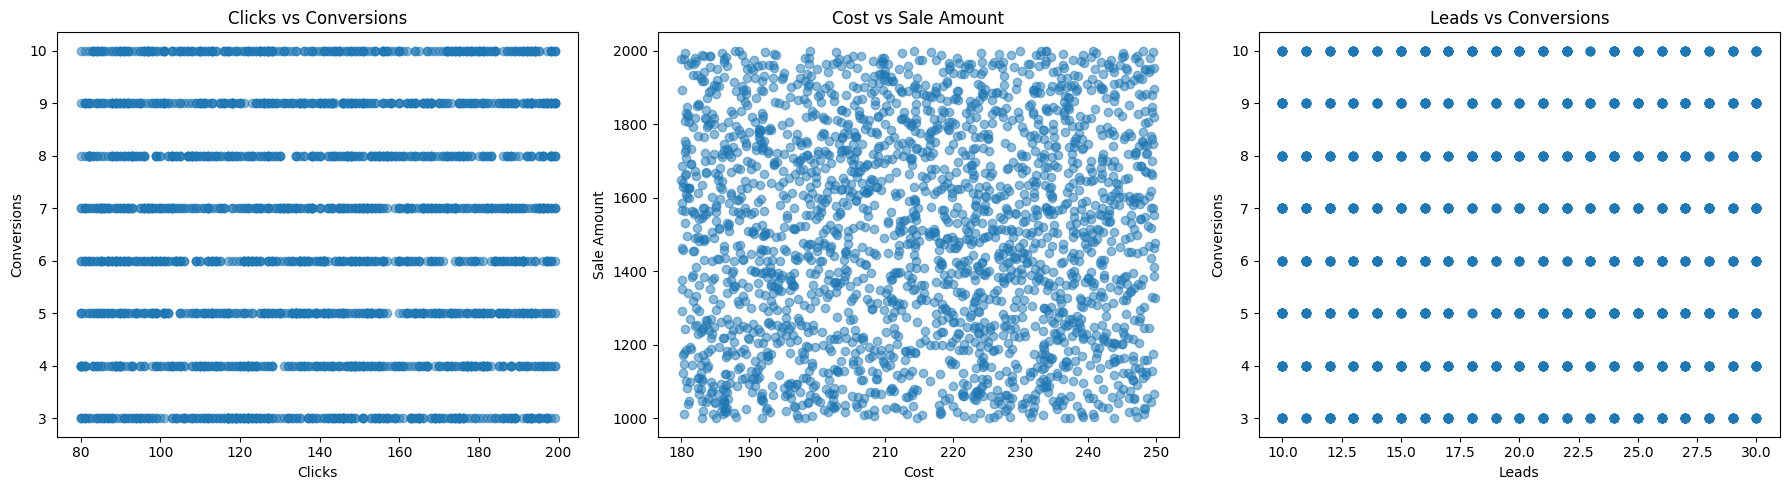

In [156]:
# Cell 53: Scatter Plot Relationships

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(
    df_clean['Clicks'],
    df_clean['Conversions'],
    alpha=0.5
)
axes[0].set_title('Clicks vs Conversions')
axes[0].set_xlabel('Clicks')
axes[0].set_ylabel('Conversions')

axes[1].scatter(
    df_clean['Cost'],
    df_clean['Sale_Amount'],
    alpha=0.5
)
axes[1].set_title('Cost vs Sale Amount')
axes[1].set_xlabel('Cost')
axes[1].set_ylabel('Sale Amount')

axes[2].scatter(
    df_clean['Leads'],
    df_clean['Conversions'],
    alpha=0.5
)
axes[2].set_title('Leads vs Conversions')
axes[2].set_xlabel('Leads')
axes[2].set_ylabel('Conversions')

plt.tight_layout()
plt.show()

In [157]:
# Cell 54: Recalculate Conversion Rate Where Possible

# Calculate Conversion Rate only when Clicks and Conversions are available
valid_rate = (
    df_clean['Clicks'].notna() &
    df_clean['Conversions'].notna() &
    (df_clean['Clicks'] > 0)
)

df_clean.loc[valid_rate, 'Conversion Rate'] = (
    df_clean.loc[valid_rate, 'Conversions']
    / df_clean.loc[valid_rate, 'Clicks']
)

print("Conversion Rate recalculated for:",
      valid_rate.sum(), "records")

print("Remaining missing Conversion Rate:",
      df_clean['Conversion Rate'].isna().sum())

Conversion Rate recalculated for: 2417 records
Remaining missing Conversion Rate: 153


In [158]:
# Cell 55: Validate Recalculated Conversion Rate

print("Conversion Rate summary:")
display(df_clean['Conversion Rate'].describe())

print("\nMissing Conversion Rate:",
      df_clean['Conversion Rate'].isna().sum())

print("\nMinimum Conversion Rate:",
      df_clean['Conversion Rate'].min())

print("Maximum Conversion Rate:",
      df_clean['Conversion Rate'].max())

Conversion Rate summary:


,Conversion Rate
count,2447.000000
mean,0.050097
std,0.022494
min,0.015075
25%,0.032680
50%,0.046875
75%,0.063063
max,0.125000



Missing Conversion Rate: 153

Minimum Conversion Rate: 0.01507537688442211
Maximum Conversion Rate: 0.125


In [159]:
# Cell 56: Check Negative Values

numeric_columns = [
    'Clicks',
    'Impressions',
    'Cost',
    'Leads',
    'Conversions',
    'Conversion Rate',
    'Sale_Amount'
]

for column in numeric_columns:
    negative_count = (df_clean[column] < 0).sum()
    print(f"{column}: {negative_count} negative values")

Clicks: 0 negative values
Impressions: 0 negative values
Cost: 0 negative values
Leads: 0 negative values
Conversions: 0 negative values
Conversion Rate: 0 negative values
Sale_Amount: 0 negative values


In [160]:
# Cell 57: Check Logical Consistency

print("Conversions greater than Leads:",
      (df_clean['Conversions'] > df_clean['Leads']).sum())

print("Clicks greater than Impressions:",
      (df_clean['Clicks'] > df_clean['Impressions']).sum())

print("Conversion Rate greater than 100%:",
      (df_clean['Conversion Rate'] > 1).sum())

print("Zero Clicks:",
      (df_clean['Clicks'] == 0).sum())

print("Zero Impressions:",
      (df_clean['Impressions'] == 0).sum())

Conversions greater than Leads: 0
Clicks greater than Impressions: 0
Conversion Rate greater than 100%: 0
Zero Clicks: 0
Zero Impressions: 0


In [161]:
# Cell 58: Final Duplicate Check

print("Duplicate rows:", df_clean.duplicated().sum())

print("Duplicate Ad_IDs:",
      df_clean['Ad_ID'].duplicated().sum())

Duplicate rows: 0
Duplicate Ad_IDs: 0


In [162]:
# Cell 59: Final Data Types

print(df_clean.dtypes)

Ad_ID                            object
Campaign_Name                    object
Clicks                          float64
Impressions                     float64
Cost                            float64
Leads                           float64
Conversions                     float64
Conversion Rate                 float64
Sale_Amount                     float64
Ad_Date                  datetime64[ns]
Location                         object
Device                           object
Keyword                          object
Missing_Count_Per_Row             int64
dtype: object


In [163]:
# Cell 60: Final Missing Value Summary

final_missing = pd.DataFrame({
    'Column': df_clean.columns,
    'Missing_Count': df_clean.isna().sum().values,
    'Missing_Percentage': (
        df_clean.isna().sum().values / len(df_clean) * 100
    )
})

display(
    final_missing.sort_values(
        by='Missing_Count',
        ascending=False
    )
)

,Column,Missing_Count,Missing_Percentage
7,Conversion Rate,153,5.884615
8,Sale_Amount,139,5.346154
2,Clicks,112,4.307692
4,Cost,97,3.730769
6,Conversions,74,2.846154
3,Impressions,54,2.076923
5,Leads,48,1.846154
1,Campaign_Name,0,0.000000
0,Ad_ID,0,0.000000
9,Ad_Date,0,0.000000


In [164]:
# Cell 61: Remove Temporary Diagnostic Column

df_clean.drop(
    columns=['Missing_Count_Per_Row'],
    inplace=True
)

print("Temporary diagnostic column removed.")
print("Dataset shape:", df_clean.shape)

Temporary diagnostic column removed.
Dataset shape: (2600, 13)


In [165]:
# Cell 62: Final Clean Dataset Overview

print("Final dataset shape:", df_clean.shape)

print("\nColumns:")
print(df_clean.columns.tolist())

print("\nData types:")
print(df_clean.dtypes)

print("\nMissing values:")
display(df_clean.isna().sum())

print("\nFirst 5 records:")
display(df_clean.head())

Final dataset shape: (2600, 13)

Columns:
['Ad_ID', 'Campaign_Name', 'Clicks', 'Impressions', 'Cost', 'Leads', 'Conversions', 'Conversion Rate', 'Sale_Amount', 'Ad_Date', 'Location', 'Device', 'Keyword']

Data types:
Ad_ID                      object
Campaign_Name              object
Clicks                    float64
Impressions               float64
Cost                      float64
Leads                     float64
Conversions               float64
Conversion Rate           float64
Sale_Amount               float64
Ad_Date            datetime64[ns]
Location                   object
Device                     object
Keyword                    object
dtype: object

Missing values:


,0
Ad_ID,0
Campaign_Name,0
Clicks,112
Impressions,54
Cost,97
Leads,48
Conversions,74
Conversion Rate,153
Sale_Amount,139
Ad_Date,0



First 5 records:


,Ad_ID,Campaign_Name,Clicks,Impressions,Cost,Leads,Conversions,Conversion Rate,Sale_Amount,Ad_Date,Location,Device,Keyword
0,A1000,Data Analytics Course,104.0,4498.0,231.88,14.0,7.0,0.067308,1892.0,2024-11-16,Hyderabad,Desktop,learn data analytics
1,A1001,Data Analytics Course,173.0,5107.0,216.84,10.0,8.0,0.046243,1679.0,2024-11-20,Hyderabad,Mobile,data analytics course
2,A1002,Data Analytics Course,90.0,4544.0,203.66,26.0,9.0,0.100000,1624.0,2024-11-16,Hyderabad,Desktop,data analytics online
3,A1003,Data Analytics Course,142.0,3185.0,237.66,17.0,6.0,0.042254,1225.0,2024-11-26,Hyderabad,Tablet,data analytics training
4,A1004,Data Analytics Course,156.0,3361.0,195.90,30.0,8.0,0.051282,1091.0,2024-11-22,Hyderabad,Desktop,online data analytic


In [166]:
# Cell 63: Overall Advertising Performance Summary

performance_columns = [
    'Clicks',
    'Impressions',
    'Cost',
    'Leads',
    'Conversions',
    'Conversion Rate',
    'Sale_Amount'
]

overall_summary = df_clean[performance_columns].describe().T

display(overall_summary)

,count,mean,std,min,25%,50%,75%,max
Clicks,2488.0,138.956994,34.619376,80.000000,110.00000,139.000000,169.000000,199.000
Impressions,2546.0,4523.280833,869.927913,3000.000000,3764.00000,4518.500000,5279.500000,5999.000
Cost,2503.0,215.090623,20.289598,180.010000,197.54000,215.570000,232.990000,249.890
Leads,2552.0,20.003918,6.032317,10.000000,15.00000,20.000000,25.000000,30.000
Conversions,2526.0,6.519002,2.272573,3.000000,5.00000,7.000000,9.000000,10.000
Conversion Rate,2447.0,0.050097,0.022494,0.015075,0.03268,0.046875,0.063063,0.125
Sale_Amount,2461.0,1498.648111,287.106579,1000.000000,1248.00000,1505.000000,1742.000000,2000.000


In [167]:
# Cell 64: Overall Advertising Totals

overall_totals = pd.DataFrame({
    'Metric': [
        'Total Impressions',
        'Total Clicks',
        'Total Leads',
        'Total Conversions',
        'Total Cost',
        'Total Sales'
    ],
    'Value': [
        df_clean['Impressions'].sum(),
        df_clean['Clicks'].sum(),
        df_clean['Leads'].sum(),
        df_clean['Conversions'].sum(),
        df_clean['Cost'].sum(),
        df_clean['Sale_Amount'].sum()
    ]
})

display(overall_totals)

,Metric,Value
0,Total Impressions,11516273.00
1,Total Clicks,345725.00
2,Total Leads,51050.00
3,Total Conversions,16467.00
4,Total Cost,538371.83
5,Total Sales,3688173.00


In [168]:
# Cell 65: Core Advertising KPIs

total_impressions = df_clean['Impressions'].sum()
total_clicks = df_clean['Clicks'].sum()
total_leads = df_clean['Leads'].sum()
total_conversions = df_clean['Conversions'].sum()
total_cost = df_clean['Cost'].sum()
total_sales = df_clean['Sale_Amount'].sum()

ctr = total_clicks / total_impressions
cpc = total_cost / total_clicks
cpl = total_cost / total_leads
overall_conversion_rate = total_conversions / total_clicks
cpa = total_cost / total_conversions
roas = total_sales / total_cost
roi = ((total_sales - total_cost) / total_cost) * 100

kpi_summary = pd.DataFrame({
    'KPI': [
        'CTR',
        'CPC',
        'CPL',
        'Conversion Rate',
        'CPA',
        'ROAS',
        'ROI'
    ],
    'Value': [
        ctr,
        cpc,
        cpl,
        overall_conversion_rate,
        cpa,
        roas,
        roi
    ]
})

display(kpi_summary)

,KPI,Value
0,CTR,0.030021
1,CPC,1.557226
2,CPL,10.545971
3,Conversion Rate,0.047630
4,CPA,32.693984
5,ROAS,6.850605
6,ROI,585.060546


In [169]:
# Cell 66: Presentation-Friendly KPI Summary

kpi_display = pd.DataFrame({
    'KPI': [
        'Click-Through Rate (CTR)',
        'Cost Per Click (CPC)',
        'Cost Per Lead (CPL)',
        'Conversion Rate',
        'Cost Per Acquisition (CPA)',
        'Return on Ad Spend (ROAS)',
        'Return on Investment (ROI)'
    ],
    'Value': [
        f"{ctr * 100:.2f}%",
        f"₹{cpc:.2f}",
        f"₹{cpl:.2f}",
        f"{overall_conversion_rate * 100:.2f}%",
        f"₹{cpa:.2f}",
        f"{roas:.2f}x",
        f"{roi:.2f}%"
    ]
})

display(kpi_display)

,KPI,Value
0,Click-Through Rate (CTR),3.00%
1,Cost Per Click (CPC),₹1.56
2,Cost Per Lead (CPL),₹10.55
3,Conversion Rate,4.76%
4,Cost Per Acquisition (CPA),₹32.69
5,Return on Ad Spend (ROAS),6.85x
6,Return on Investment (ROI),585.06%


In [170]:
# Cell 67: Keyword Performance Summary

keyword_performance = (
    df_clean
    .groupby('Keyword')
    .agg(
        Records=('Ad_ID', 'count'),
        Impressions=('Impressions', 'sum'),
        Clicks=('Clicks', 'sum'),
        Leads=('Leads', 'sum'),
        Conversions=('Conversions', 'sum'),
        Cost=('Cost', 'sum'),
        Sales=('Sale_Amount', 'sum')
    )
    .reset_index()
)

# Calculate keyword-level KPIs
keyword_performance['CTR'] = (
    keyword_performance['Clicks'] /
    keyword_performance['Impressions']
)

keyword_performance['CPC'] = (
    keyword_performance['Cost'] /
    keyword_performance['Clicks']
)

keyword_performance['Conversion_Rate'] = (
    keyword_performance['Conversions'] /
    keyword_performance['Clicks']
)

keyword_performance['CPA'] = (
    keyword_performance['Cost'] /
    keyword_performance['Conversions']
)

keyword_performance['ROAS'] = (
    keyword_performance['Sales'] /
    keyword_performance['Cost']
)

keyword_performance['ROI_%'] = (
    (keyword_performance['Sales'] -
     keyword_performance['Cost']) /
    keyword_performance['Cost']
) * 100

display(keyword_performance)

,Keyword,Records,Impressions,Clicks,Leads,Conversions,Cost,Sales,CTR,CPC,Conversion_Rate,CPA,ROAS,ROI_%
0,analytics for data,429,1950444.0,56021.0,8604.0,2687.0,89072.83,612229.0,0.028722,1.589990,0.047964,33.149546,6.873353,587.335296
1,data analytics course,440,1966691.0,59369.0,8673.0,2806.0,90792.01,634723.0,0.030187,1.529283,0.047264,32.356383,6.990957,599.095658
2,data analytics online,420,1848220.0,55931.0,8185.0,2628.0,85859.33,579245.0,0.030262,1.535094,0.046986,32.670978,6.746442,574.644212
3,data analytics training,414,1835565.0,54786.0,8008.0,2654.0,85449.43,590040.0,0.029847,1.559695,0.048443,32.196469,6.905137,590.513676
4,learn data analytics,444,1920160.0,58698.0,8777.0,2823.0,93497.47,643359.0,0.030569,1.592856,0.048094,33.119897,6.881031,588.103111
5,online data analytic,453,1995193.0,60920.0,8803.0,2869.0,93700.76,628577.0,0.030533,1.538095,0.047095,32.659728,6.708345,570.834473


In [171]:
# Cell 68: Keyword Performance Ranked by ROAS

keyword_roas = keyword_performance.sort_values(
    by='ROAS',
    ascending=False
)

display(
    keyword_roas[
        [
            'Keyword',
            'Records',
            'Clicks',
            'Conversions',
            'Cost',
            'Sales',
            'Conversion_Rate',
            'CPA',
            'ROAS',
            'ROI_%'
        ]
    ]
)

,Keyword,Records,Clicks,Conversions,Cost,Sales,Conversion_Rate,CPA,ROAS,ROI_%
1,data analytics course,440,59369.0,2806.0,90792.01,634723.0,0.047264,32.356383,6.990957,599.095658
3,data analytics training,414,54786.0,2654.0,85449.43,590040.0,0.048443,32.196469,6.905137,590.513676
4,learn data analytics,444,58698.0,2823.0,93497.47,643359.0,0.048094,33.119897,6.881031,588.103111
0,analytics for data,429,56021.0,2687.0,89072.83,612229.0,0.047964,33.149546,6.873353,587.335296
2,data analytics online,420,55931.0,2628.0,85859.33,579245.0,0.046986,32.670978,6.746442,574.644212
5,online data analytic,453,60920.0,2869.0,93700.76,628577.0,0.047095,32.659728,6.708345,570.834473


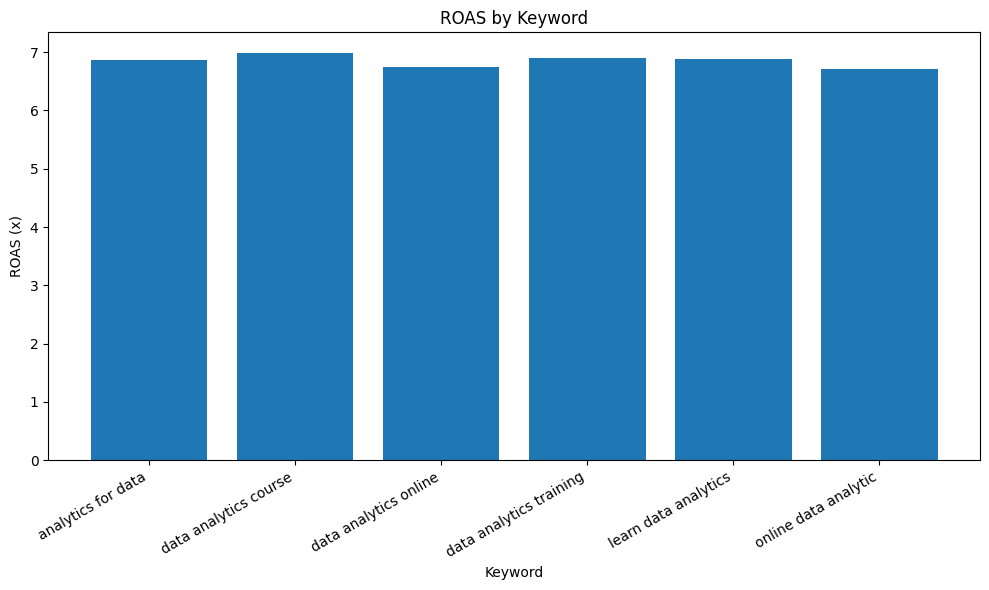

In [172]:
# Cell 69: Keyword Performance - ROAS

plt.figure(figsize=(10, 6))

plt.bar(
    keyword_performance['Keyword'],
    keyword_performance['ROAS']
)

plt.title('ROAS by Keyword')
plt.xlabel('Keyword')
plt.ylabel('ROAS (x)')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

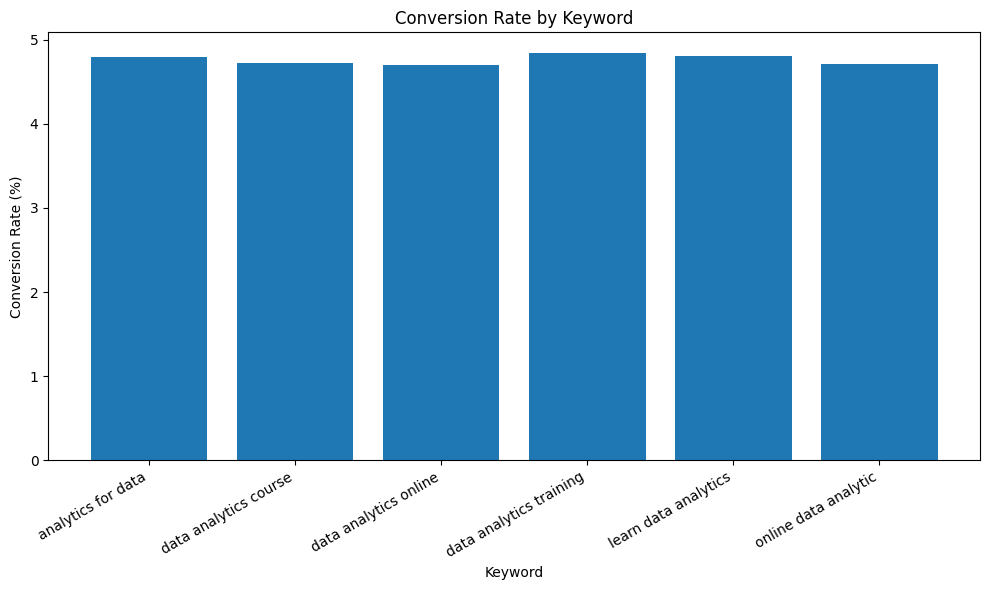

In [173]:
# Cell 70: Keyword Conversion Rate

plt.figure(figsize=(10, 6))

plt.bar(
    keyword_performance['Keyword'],
    keyword_performance['Conversion_Rate'] * 100
)

plt.title('Conversion Rate by Keyword')
plt.xlabel('Keyword')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

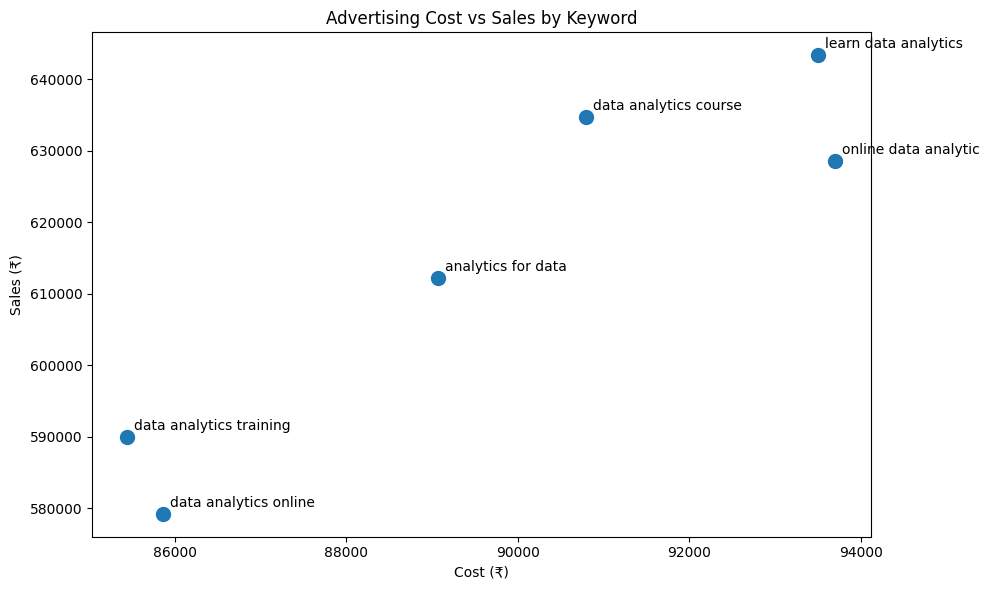

In [174]:
# Cell 71: Keyword Cost vs Sales

plt.figure(figsize=(10, 6))

plt.scatter(
    keyword_performance['Cost'],
    keyword_performance['Sales'],
    s=100
)

for _, row in keyword_performance.iterrows():
    plt.annotate(
        row['Keyword'],
        (row['Cost'], row['Sales']),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.title('Advertising Cost vs Sales by Keyword')
plt.xlabel('Cost (₹)')
plt.ylabel('Sales (₹)')

plt.tight_layout()
plt.show()

In [175]:
# Cell 72: Device Performance Summary

device_performance = (
    df_clean
    .groupby('Device')
    .agg(
        Records=('Ad_ID', 'count'),
        Impressions=('Impressions', 'sum'),
        Clicks=('Clicks', 'sum'),
        Leads=('Leads', 'sum'),
        Conversions=('Conversions', 'sum'),
        Cost=('Cost', 'sum'),
        Sales=('Sale_Amount', 'sum')
    )
    .reset_index()
)

device_performance['CTR'] = (
    device_performance['Clicks'] /
    device_performance['Impressions']
)

device_performance['CPC'] = (
    device_performance['Cost'] /
    device_performance['Clicks']
)

device_performance['Conversion_Rate'] = (
    device_performance['Conversions'] /
    device_performance['Clicks']
)

device_performance['CPA'] = (
    device_performance['Cost'] /
    device_performance['Conversions']
)

device_performance['ROAS'] = (
    device_performance['Sales'] /
    device_performance['Cost']
)

device_performance['ROI_%'] = (
    (device_performance['Sales'] -
     device_performance['Cost']) /
    device_performance['Cost']
) * 100

display(device_performance)

,Device,Records,Impressions,Clicks,Leads,Conversions,Cost,Sales,CTR,CPC,Conversion_Rate,CPA,ROAS,ROI_%
0,Desktop,888,3924220.0,116605.0,17310.0,5632.0,183786.04,1264233.0,0.029714,1.576142,0.048300,32.632464,6.878830,587.883041
1,Mobile,878,3903810.0,118342.0,17427.0,5645.0,183558.31,1235809.0,0.030314,1.551083,0.047701,32.516973,6.732515,573.251459
2,Tablet,834,3688243.0,110778.0,16313.0,5190.0,171027.48,1188131.0,0.030035,1.543876,0.046850,32.953272,6.947018,594.701810


In [176]:
# Cell 73: Device Performance Comparison

device_comparison = device_performance[
    [
        'Device',
        'Records',
        'Clicks',
        'Conversions',
        'Cost',
        'Sales',
        'CTR',
        'Conversion_Rate',
        'CPA',
        'ROAS',
        'ROI_%'
    ]
].copy()

display(device_comparison)

,Device,Records,Clicks,Conversions,Cost,Sales,CTR,Conversion_Rate,CPA,ROAS,ROI_%
0,Desktop,888,116605.0,5632.0,183786.04,1264233.0,0.029714,0.048300,32.632464,6.878830,587.883041
1,Mobile,878,118342.0,5645.0,183558.31,1235809.0,0.030314,0.047701,32.516973,6.732515,573.251459
2,Tablet,834,110778.0,5190.0,171027.48,1188131.0,0.030035,0.046850,32.953272,6.947018,594.701810


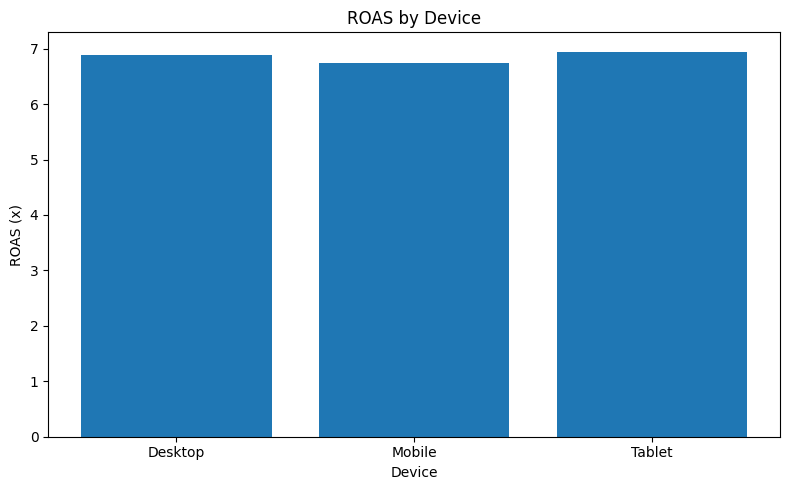

In [177]:
# Cell 74: ROAS by Device

plt.figure(figsize=(8, 5))

plt.bar(
    device_performance['Device'],
    device_performance['ROAS']
)

plt.title('ROAS by Device')
plt.xlabel('Device')
plt.ylabel('ROAS (x)')

plt.tight_layout()
plt.show()

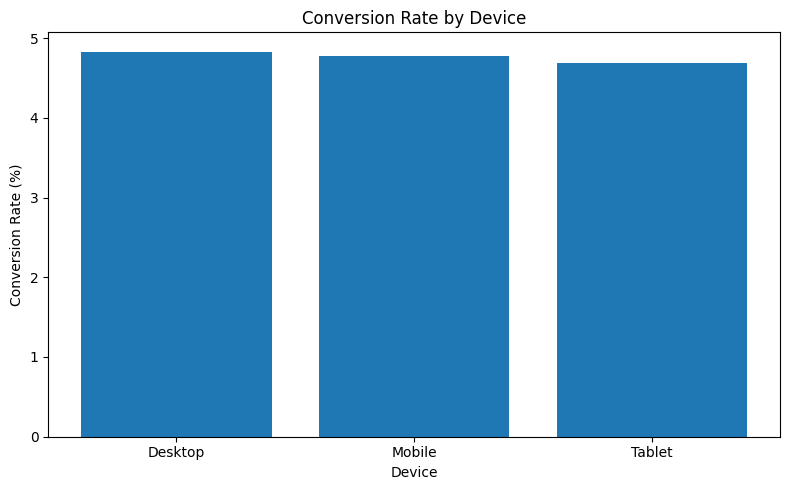

In [178]:
# Cell 75: Conversion Rate by Device

plt.figure(figsize=(8, 5))

plt.bar(
    device_performance['Device'],
    device_performance['Conversion_Rate'] * 100
)

plt.title('Conversion Rate by Device')
plt.xlabel('Device')
plt.ylabel('Conversion Rate (%)')

plt.tight_layout()
plt.show()

In [179]:
# Cell 76: Daily Advertising Performance

daily_performance = (
    df_clean
    .groupby('Ad_Date')
    .agg(
        Records=('Ad_ID', 'count'),
        Impressions=('Impressions', 'sum'),
        Clicks=('Clicks', 'sum'),
        Leads=('Leads', 'sum'),
        Conversions=('Conversions', 'sum'),
        Cost=('Cost', 'sum'),
        Sales=('Sale_Amount', 'sum')
    )
    .reset_index()
    .sort_values('Ad_Date')
)

daily_performance['CTR'] = (
    daily_performance['Clicks'] /
    daily_performance['Impressions']
)

daily_performance['Conversion_Rate'] = (
    daily_performance['Conversions'] /
    daily_performance['Clicks']
)

daily_performance['ROAS'] = (
    daily_performance['Sales'] /
    daily_performance['Cost']
)

display(daily_performance)

,Ad_Date,Records,Impressions,Clicks,Leads,Conversions,Cost,Sales,CTR,Conversion_Rate,ROAS
0,2024-11-01,76,322753.0,10353.0,1503.0,486.0,16694.92,107250.0,0.032077,0.046943,6.424110
1,2024-11-02,87,386843.0,10785.0,1722.0,545.0,18056.12,125962.0,0.027880,0.050533,6.976139
2,2024-11-03,78,367650.0,10689.0,1597.0,475.0,16280.61,110400.0,0.029074,0.044438,6.781073
3,2024-11-04,82,363364.0,11834.0,1642.0,503.0,17316.51,120534.0,0.032568,0.042505,6.960640
4,2024-11-05,92,401819.0,12792.0,1812.0,563.0,18774.41,130855.0,0.031835,0.044012,6.969860
5,2024-11-06,74,320285.0,10462.0,1477.0,460.0,15649.89,101639.0,0.032665,0.043969,6.494550
6,2024-11-07,84,372561.0,10972.0,1582.0,520.0,17347.79,123203.0,0.029450,0.047393,7.101942
7,2024-11-08,89,380671.0,12002.0,1821.0,595.0,18969.14,127913.0,0.031529,0.049575,6.743216
8,2024-11-09,80,352022.0,10876.0,1521.0,523.0,16570.16,112193.0,0.030896,0.048088,6.770786
9,2024-11-10,82,349945.0,10567.0,1668.0,529.0,16694.96,115647.0,0.030196,0.050062,6.927061


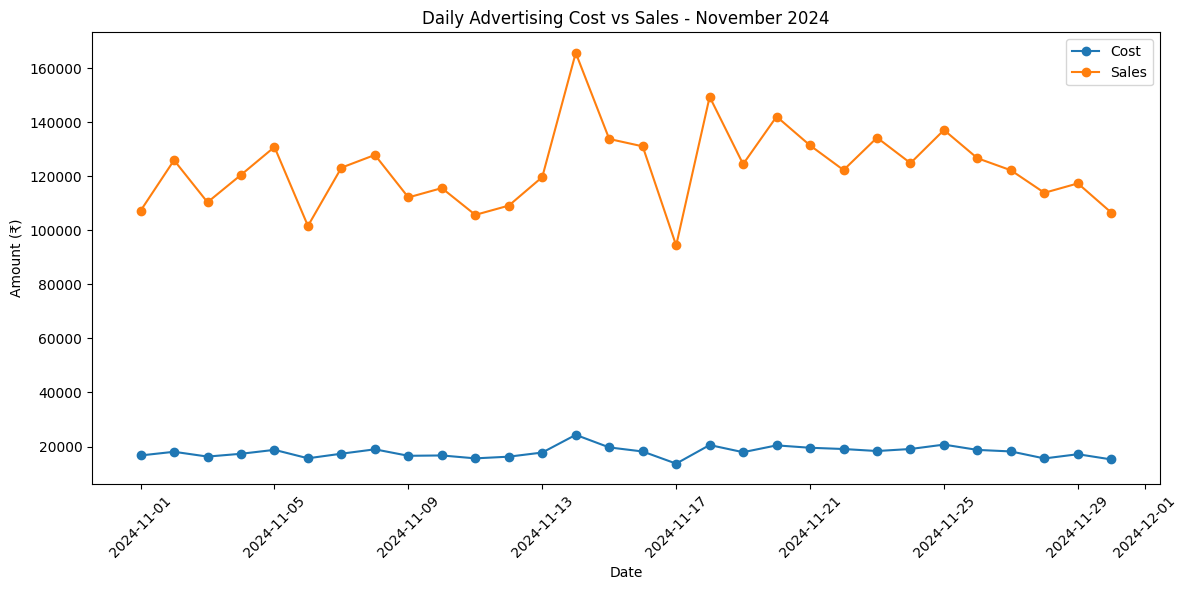

In [180]:
# Cell 77: Daily Cost vs Sales

plt.figure(figsize=(12, 6))

plt.plot(
    daily_performance['Ad_Date'],
    daily_performance['Cost'],
    marker='o',
    label='Cost'
)

plt.plot(
    daily_performance['Ad_Date'],
    daily_performance['Sales'],
    marker='o',
    label='Sales'
)

plt.title('Daily Advertising Cost vs Sales - November 2024')
plt.xlabel('Date')
plt.ylabel('Amount (₹)')
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

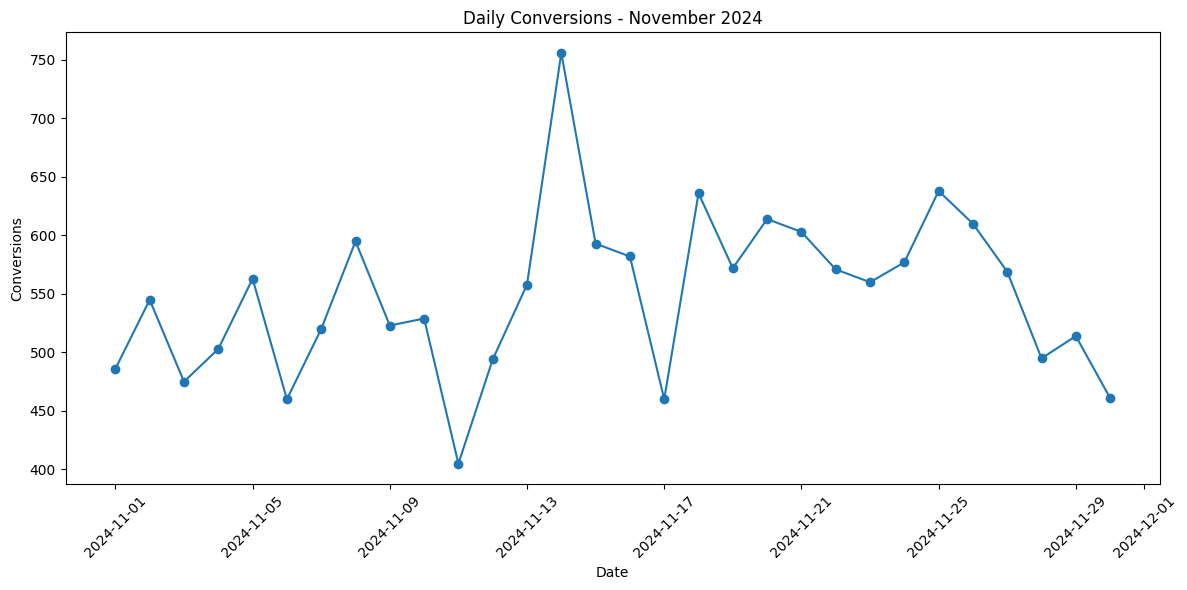

In [181]:
# Cell 78: Daily Conversions

plt.figure(figsize=(12, 6))

plt.plot(
    daily_performance['Ad_Date'],
    daily_performance['Conversions'],
    marker='o'
)

plt.title('Daily Conversions - November 2024')
plt.xlabel('Date')
plt.ylabel('Conversions')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

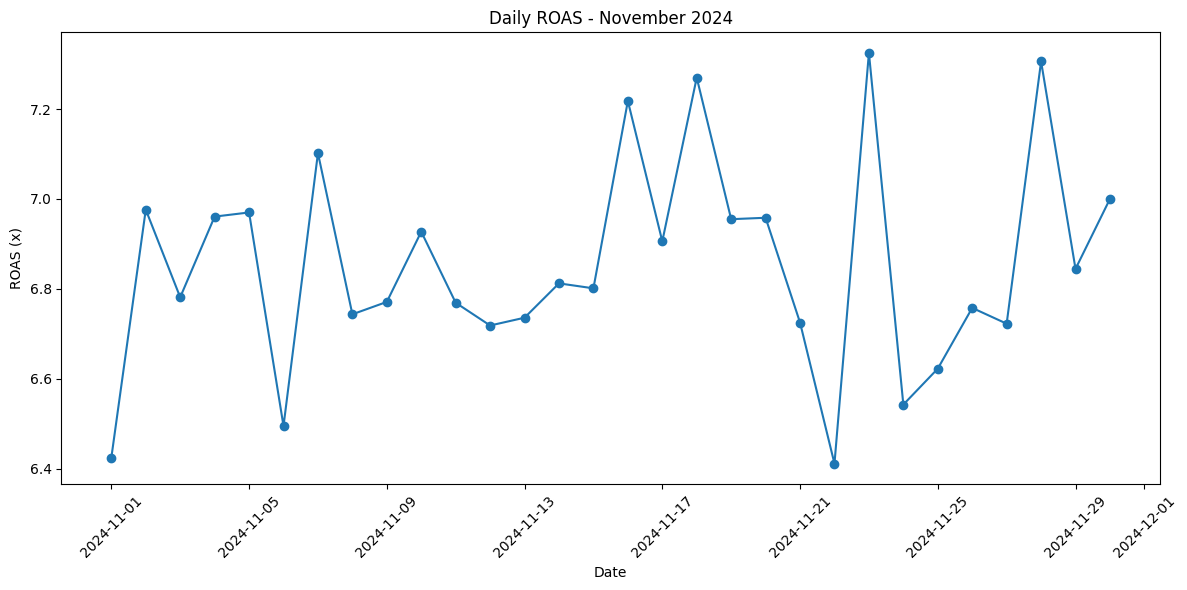

In [182]:
# Cell 79: Daily ROAS

plt.figure(figsize=(12, 6))

plt.plot(
    daily_performance['Ad_Date'],
    daily_performance['ROAS'],
    marker='o'
)

plt.title('Daily ROAS - November 2024')
plt.xlabel('Date')
plt.ylabel('ROAS (x)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [183]:
# Cell 80: Correlation Matrix

correlation_columns = [
    'Clicks',
    'Impressions',
    'Cost',
    'Leads',
    'Conversions',
    'Conversion Rate',
    'Sale_Amount'
]

correlation_matrix = df_clean[correlation_columns].corr()

display(correlation_matrix)

,Clicks,Impressions,Cost,Leads,Conversions,Conversion Rate,Sale_Amount
Clicks,1.000000,0.001500,0.034541,0.054291,0.006728,-0.580416,0.036881
Impressions,0.001500,1.000000,0.000671,-0.035502,-0.013960,-0.009418,-0.008431
Cost,0.034541,0.000671,1.000000,-0.009370,0.003917,0.004950,0.010845
Leads,0.054291,-0.035502,-0.009370,1.000000,0.023439,-0.012353,0.011950
Conversions,0.006728,-0.013960,0.003917,0.023439,1.000000,0.766485,-0.003052
Conversion Rate,-0.580416,-0.009418,0.004950,-0.012353,0.766485,1.000000,-0.025140
Sale_Amount,0.036881,-0.008431,0.010845,0.011950,-0.003052,-0.025140,1.000000


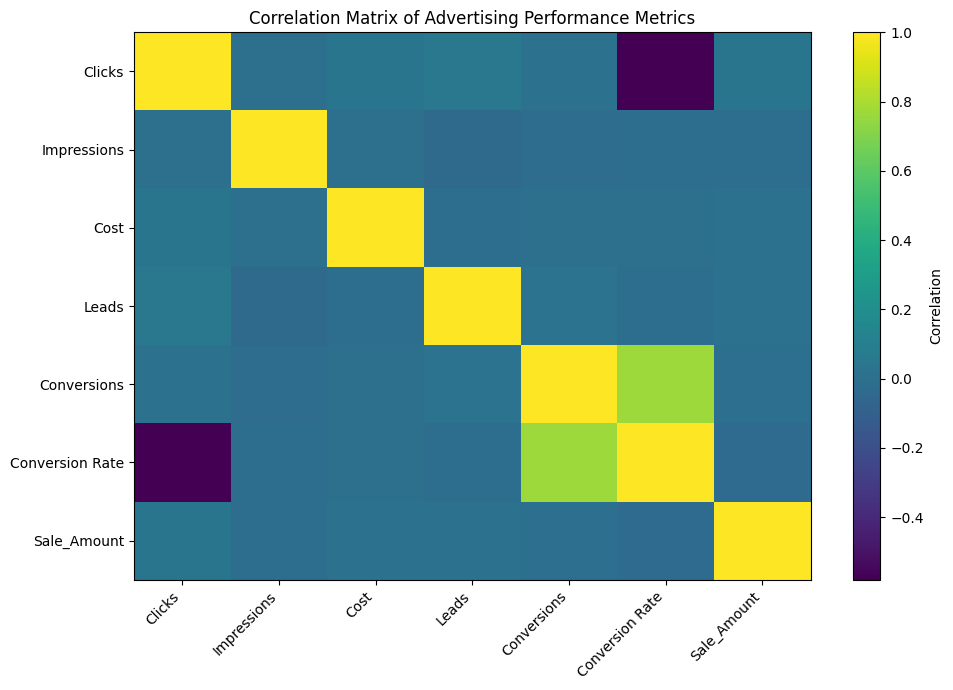

In [184]:
# Cell 81: Correlation Heatmap

plt.figure(figsize=(10, 7))

plt.imshow(
    correlation_matrix,
    interpolation='nearest',
    aspect='auto'
)

plt.colorbar(label='Correlation')

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title('Correlation Matrix of Advertising Performance Metrics')

plt.tight_layout()
plt.show()

In [185]:
# Cell 82: Strongest Variable Relationships

corr_pairs = (
    correlation_matrix
    .where(
        ~np.eye(correlation_matrix.shape[0], dtype=bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = ['Variable_1', 'Variable_2', 'Correlation']

corr_pairs['Absolute_Correlation'] = (
    corr_pairs['Correlation'].abs()
)

strongest_relationships = (
    corr_pairs
    .sort_values('Absolute_Correlation', ascending=False)
)

display(strongest_relationships.head(10))

,Variable_1,Variable_2,Correlation,Absolute_Correlation
28,Conversions,Conversion Rate,0.766485,0.766485
34,Conversion Rate,Conversions,0.766485,0.766485
4,Clicks,Conversion Rate,-0.580416,0.580416
30,Conversion Rate,Clicks,-0.580416,0.580416
18,Leads,Clicks,0.054291,0.054291
2,Clicks,Leads,0.054291,0.054291
5,Clicks,Sale_Amount,0.036881,0.036881
36,Sale_Amount,Clicks,0.036881,0.036881
19,Leads,Impressions,-0.035502,0.035502
8,Impressions,Leads,-0.035502,0.035502


In [186]:
# Cell 83: Final Performance Snapshot

# Ensure important numeric columns are numeric
numeric_cols = [
    'Clicks',
    'Impressions',
    'Cost',
    'Leads',
    'Conversions',
    'Sale_Amount'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Recalculate overall performance metrics
total_impressions = df['Impressions'].sum()
total_clicks = df['Clicks'].sum()
total_cost = df['Cost'].sum()
total_leads = df['Leads'].sum()
total_conversions = df['Conversions'].sum()
total_sales = df['Sale_Amount'].sum()

overall_ctr = (total_clicks / total_impressions) * 100
overall_conversion_rate = (total_conversions / total_clicks) * 100
overall_cpl = total_cost / total_leads
overall_cpa = total_cost / total_conversions
overall_roas = total_sales / total_cost

# Display final performance snapshot
final_performance = pd.DataFrame({
    'Metric': [
        'Total Impressions',
        'Total Clicks',
        'Total Cost',
        'Total Leads',
        'Total Conversions',
        'Total Sales',
        'Overall CTR (%)',
        'Overall Conversion Rate (%)',
        'Cost Per Lead',
        'Cost Per Conversion',
        'ROAS'
    ],
    'Value': [
        total_impressions,
        total_clicks,
        total_cost,
        total_leads,
        total_conversions,
        total_sales,
        overall_ctr,
        overall_conversion_rate,
        overall_cpl,
        overall_cpa,
        overall_roas
    ]
})

final_performance

/tmp/ipykernel_371/669816752.py:28: RuntimeWarning: invalid value encountered in scalar divide
  overall_roas = total_sales / total_cost


,Metric,Value
0,Total Impressions,1.151627e+07
1,Total Clicks,3.457250e+05
2,Total Cost,0.000000e+00
3,Total Leads,5.105000e+04
4,Total Conversions,1.646700e+04
5,Total Sales,0.000000e+00
6,Overall CTR (%),3.002056e+00
7,Overall Conversion Rate (%),4.763034e+00
8,Cost Per Lead,0.000000e+00
9,Cost Per Conversion,0.000000e+00


In [187]:
# Cell 84: Diagnose Cost and Sale_Amount

print("COST COLUMN")
print("Data type:", df['Cost'].dtype)
print("Non-zero values:", (df['Cost'] != 0).sum())
print("Zero values:", (df['Cost'] == 0).sum())
print("Missing values:", df['Cost'].isna().sum())
print("\nSample Cost values:")
print(df['Cost'].head(10))

print("\n" + "="*60)

print("SALE_AMOUNT COLUMN")
print("Data type:", df['Sale_Amount'].dtype)
print("Non-zero values:", (df['Sale_Amount'] != 0).sum())
print("Zero values:", (df['Sale_Amount'] == 0).sum())
print("Missing values:", df['Sale_Amount'].isna().sum())
print("\nSample Sale_Amount values:")
print(df['Sale_Amount'].head(10))

COST COLUMN
Data type: float64
Non-zero values: 2600
Zero values: 0
Missing values: 2600

Sample Cost values:
0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
5   NaN
6   NaN
7   NaN
8   NaN
9   NaN
Name: Cost, dtype: float64

SALE_AMOUNT COLUMN
Data type: float64
Non-zero values: 2600
Zero values: 0
Missing values: 2600

Sample Sale_Amount values:
0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
5   NaN
6   NaN
7   NaN
8   NaN
9   NaN
Name: Sale_Amount, dtype: float64


In [188]:
# Cell 85: Locate original dataframe containing Cost and Sale_Amount

import pandas as pd

print("DataFrames currently available in the notebook:\n")

for name, obj in globals().items():
    if isinstance(obj, pd.DataFrame):
        relevant_cols = [
            col for col in obj.columns
            if col in ['Cost', 'Sale_Amount']
        ]

        if relevant_cols:
            print(f"DataFrame: {name}")
            print(f"Shape: {obj.shape}")
            print(f"Relevant columns: {relevant_cols}")
            print()

            for col in relevant_cols:
                print(f"{col} sample values:")
                print(obj[col].head(5).tolist())
                print()

            print("-" * 70)

DataFrames currently available in the notebook:

DataFrame: df
Shape: (2600, 13)
Relevant columns: ['Cost', 'Sale_Amount']

Cost sample values:
[nan, nan, nan, nan, nan]

Sale_Amount sample values:
[nan, nan, nan, nan, nan]

----------------------------------------------------------------------
DataFrame: df_clean
Shape: (2600, 13)
Relevant columns: ['Cost', 'Sale_Amount']

Cost sample values:
[231.88, 216.84, 203.66, 237.66, 195.9]

Sale_Amount sample values:
[1892.0, 1679.0, 1624.0, 1225.0, 1091.0]

----------------------------------------------------------------------
DataFrame: invalid_date_range
Shape: (0, 13)
Relevant columns: ['Cost', 'Sale_Amount']

Cost sample values:
[]

Sale_Amount sample values:
[]

----------------------------------------------------------------------
DataFrame: correlation_matrix
Shape: (7, 7)
Relevant columns: ['Cost', 'Sale_Amount']

Cost sample values:
[0.0345413551936866, 0.000670575489195737, 1.0, -0.009369792748170494, 0.003917275552558199]

Sale_Am

In [189]:
# Cell 86: Reload Original Advertising Dataset

import pandas as pd

# Replace the filename below with the exact original dataset filename
raw_df = pd.read_csv('/content/GoogleAds_DataAnalytics_Sales_Uncleaned.csv')

print("Original dataset shape:", raw_df.shape)
print("\nOriginal Cost values:")
print(raw_df['Cost'].head())

print("\nOriginal Sale_Amount values:")
print(raw_df['Sale_Amount'].head())

Original dataset shape: (2600, 13)

Original Cost values:
0    $231.88
1    $216.84
2    $203.66
3    $237.66
4     $195.9
Name: Cost, dtype: object

Original Sale_Amount values:
0    $1892
1    $1679
2    $1624
3    $1225
4    $1091
Name: Sale_Amount, dtype: object


In [190]:
# Cell 87: Restore and Clean Cost and Sale_Amount

# Restore original values from raw dataset
df['Cost'] = raw_df['Cost'].copy()
df['Sale_Amount'] = raw_df['Sale_Amount'].copy()

# Clean Cost
df['Cost'] = (
    df['Cost']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)

df['Cost'] = pd.to_numeric(df['Cost'], errors='coerce')

# Clean Sale_Amount
df['Sale_Amount'] = (
    df['Sale_Amount']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)

df['Sale_Amount'] = pd.to_numeric(df['Sale_Amount'], errors='coerce')

# Verification
print("Cost data type:", df['Cost'].dtype)
print("Sale_Amount data type:", df['Sale_Amount'].dtype)

print("\nCost missing values:", df['Cost'].isna().sum())
print("Sale_Amount missing values:", df['Sale_Amount'].isna().sum())

print("\nCost sample:")
print(df['Cost'].head())

print("\nSale_Amount sample:")
print(df['Sale_Amount'].head())

Cost data type: float64
Sale_Amount data type: float64

Cost missing values: 97
Sale_Amount missing values: 139

Cost sample:
0    231.88
1    216.84
2    203.66
3    237.66
4    195.90
Name: Cost, dtype: float64

Sale_Amount sample:
0    1892.0
1    1679.0
2    1624.0
3    1225.0
4    1091.0
Name: Sale_Amount, dtype: float64


In [191]:
# Cell 88: Overall Advertising Performance KPIs

# Calculate totals while ignoring missing values
total_impressions = df['Impressions'].sum()
total_clicks = df['Clicks'].sum()
total_cost = df['Cost'].sum()
total_leads = df['Leads'].sum()
total_conversions = df['Conversions'].sum()
total_sales = df['Sale_Amount'].sum()

# Calculate overall performance metrics
overall_ctr = (total_clicks / total_impressions) * 100
overall_conversion_rate = (total_conversions / total_clicks) * 100
overall_cpl = total_cost / total_leads
overall_cpa = total_cost / total_conversions
overall_roas = total_sales / total_cost

# Create KPI summary
final_performance = pd.DataFrame({
    'Metric': [
        'Total Impressions',
        'Total Clicks',
        'Total Cost',
        'Total Leads',
        'Total Conversions',
        'Total Sales',
        'Overall CTR (%)',
        'Overall Conversion Rate (%)',
        'Cost Per Lead',
        'Cost Per Conversion',
        'ROAS'
    ],
    'Value': [
        total_impressions,
        total_clicks,
        total_cost,
        total_leads,
        total_conversions,
        total_sales,
        overall_ctr,
        overall_conversion_rate,
        overall_cpl,
        overall_cpa,
        overall_roas
    ]
})

# Display formatted results
final_performance

,Metric,Value
0,Total Impressions,1.151627e+07
1,Total Clicks,3.457250e+05
2,Total Cost,5.383718e+05
3,Total Leads,5.105000e+04
4,Total Conversions,1.646700e+04
5,Total Sales,3.688173e+06
6,Overall CTR (%),3.002056e+00
7,Overall Conversion Rate (%),4.763034e+00
8,Cost Per Lead,1.054597e+01
9,Cost Per Conversion,3.269398e+01


In [192]:
# Cell 89: Campaign-Level Performance Analysis

campaign_performance = df.groupby('Campaign_Name').agg(
    Records=('Ad_ID', 'count'),
    Impressions=('Impressions', 'sum'),
    Clicks=('Clicks', 'sum'),
    Cost=('Cost', 'sum'),
    Leads=('Leads', 'sum'),
    Conversions=('Conversions', 'sum'),
    Sales=('Sale_Amount', 'sum')
).reset_index()

# Calculate campaign-level KPIs
campaign_performance['CTR (%)'] = (
    campaign_performance['Clicks'] /
    campaign_performance['Impressions']
) * 100

campaign_performance['Conversion Rate (%)'] = (
    campaign_performance['Conversions'] /
    campaign_performance['Clicks']
) * 100

campaign_performance['Cost Per Lead'] = (
    campaign_performance['Cost'] /
    campaign_performance['Leads']
)

campaign_performance['Cost Per Conversion'] = (
    campaign_performance['Cost'] /
    campaign_performance['Conversions']
)

campaign_performance['ROAS'] = (
    campaign_performance['Sales'] /
    campaign_performance['Cost']
)

campaign_performance

,Campaign_Name,Records,Impressions,Clicks,Cost,Leads,Conversions,Sales,CTR (%),Conversion Rate (%),Cost Per Lead,Cost Per Conversion,ROAS
0,Data Analytcis Course,680,2981380.0,88345.0,140963.60,13582.0,4326.0,962574.0,2.963225,4.896712,10.378707,32.585206,6.828529
1,Data Analytics Corse,647,2897917.0,87882.0,135101.94,12515.0,4108.0,921485.0,3.032592,4.674450,10.795201,32.887522,6.820664
2,Data Anlytics Corse,636,2801680.0,84556.0,130168.38,12528.0,3994.0,892385.0,3.018046,4.723497,10.390196,32.590981,6.855620
3,DataAnalyticsCourse,637,2835296.0,84942.0,132137.91,12425.0,4039.0,911729.0,2.995878,4.755009,10.634842,32.715501,6.899829


In [193]:
# Cell 90: Standardize Campaign Name

# Standardize all campaign-name variants
df['Campaign_Name'] = 'Data Analytics Course'

# Verify the result
print("Unique Campaign Names:")
print(df['Campaign_Name'].value_counts())

print("\nNumber of unique campaign names:",
      df['Campaign_Name'].nunique())

Unique Campaign Names:
Campaign_Name
Data Analytics Course    2600
Name: count, dtype: int64

Number of unique campaign names: 1


In [194]:
# Cell 91: Keyword-Level Performance Analysis

keyword_performance = df.groupby('Keyword').agg(
    Records=('Ad_ID', 'count'),
    Total_Clicks=('Clicks', 'sum'),
    Total_Impressions=('Impressions', 'sum'),
    Total_Cost=('Cost', 'sum'),
    Total_Leads=('Leads', 'sum'),
    Total_Conversions=('Conversions', 'sum'),
    Total_Sales=('Sale_Amount', 'sum')
).reset_index()

# Calculate keyword-level KPIs
keyword_performance['CTR (%)'] = (
    keyword_performance['Total_Clicks'] /
    keyword_performance['Total_Impressions']
) * 100

keyword_performance['Conversion Rate (%)'] = (
    keyword_performance['Total_Conversions'] /
    keyword_performance['Total_Clicks']
) * 100

keyword_performance['Cost Per Lead'] = (
    keyword_performance['Total_Cost'] /
    keyword_performance['Total_Leads']
)

keyword_performance['Cost Per Conversion'] = (
    keyword_performance['Total_Cost'] /
    keyword_performance['Total_Conversions']
)

keyword_performance['ROAS'] = (
    keyword_performance['Total_Sales'] /
    keyword_performance['Total_Cost']
)

# Sort by ROAS for easier comparison
keyword_performance = keyword_performance.sort_values(
    by='ROAS',
    ascending=False
).reset_index(drop=True)

keyword_performance

,Keyword,Records,Total_Clicks,Total_Impressions,Total_Cost,Total_Leads,Total_Conversions,Total_Sales,CTR (%),Conversion Rate (%),Cost Per Lead,Cost Per Conversion,ROAS
0,data analytics course,440,59369.0,1966691.0,90792.01,8673.0,2806.0,634723.0,3.018725,4.726372,10.468351,32.356383,6.990957
1,data anaytics training,414,54786.0,1835565.0,85449.43,8008.0,2654.0,590040.0,2.984694,4.844303,10.670508,32.196469,6.905137
2,learn data analytics,444,58698.0,1920160.0,93497.47,8777.0,2823.0,643359.0,3.056933,4.809363,10.652554,33.119897,6.881031
3,analytics for data,429,56021.0,1950444.0,89072.83,8604.0,2687.0,612229.0,2.872218,4.796416,10.352491,33.149546,6.873353
4,data analitics online,420,55931.0,1848220.0,85859.33,8185.0,2628.0,579245.0,3.026209,4.698647,10.489839,32.670978,6.746442
5,online data analytic,453,60920.0,1995193.0,93700.76,8803.0,2869.0,628577.0,3.053339,4.709455,10.644185,32.659728,6.708345


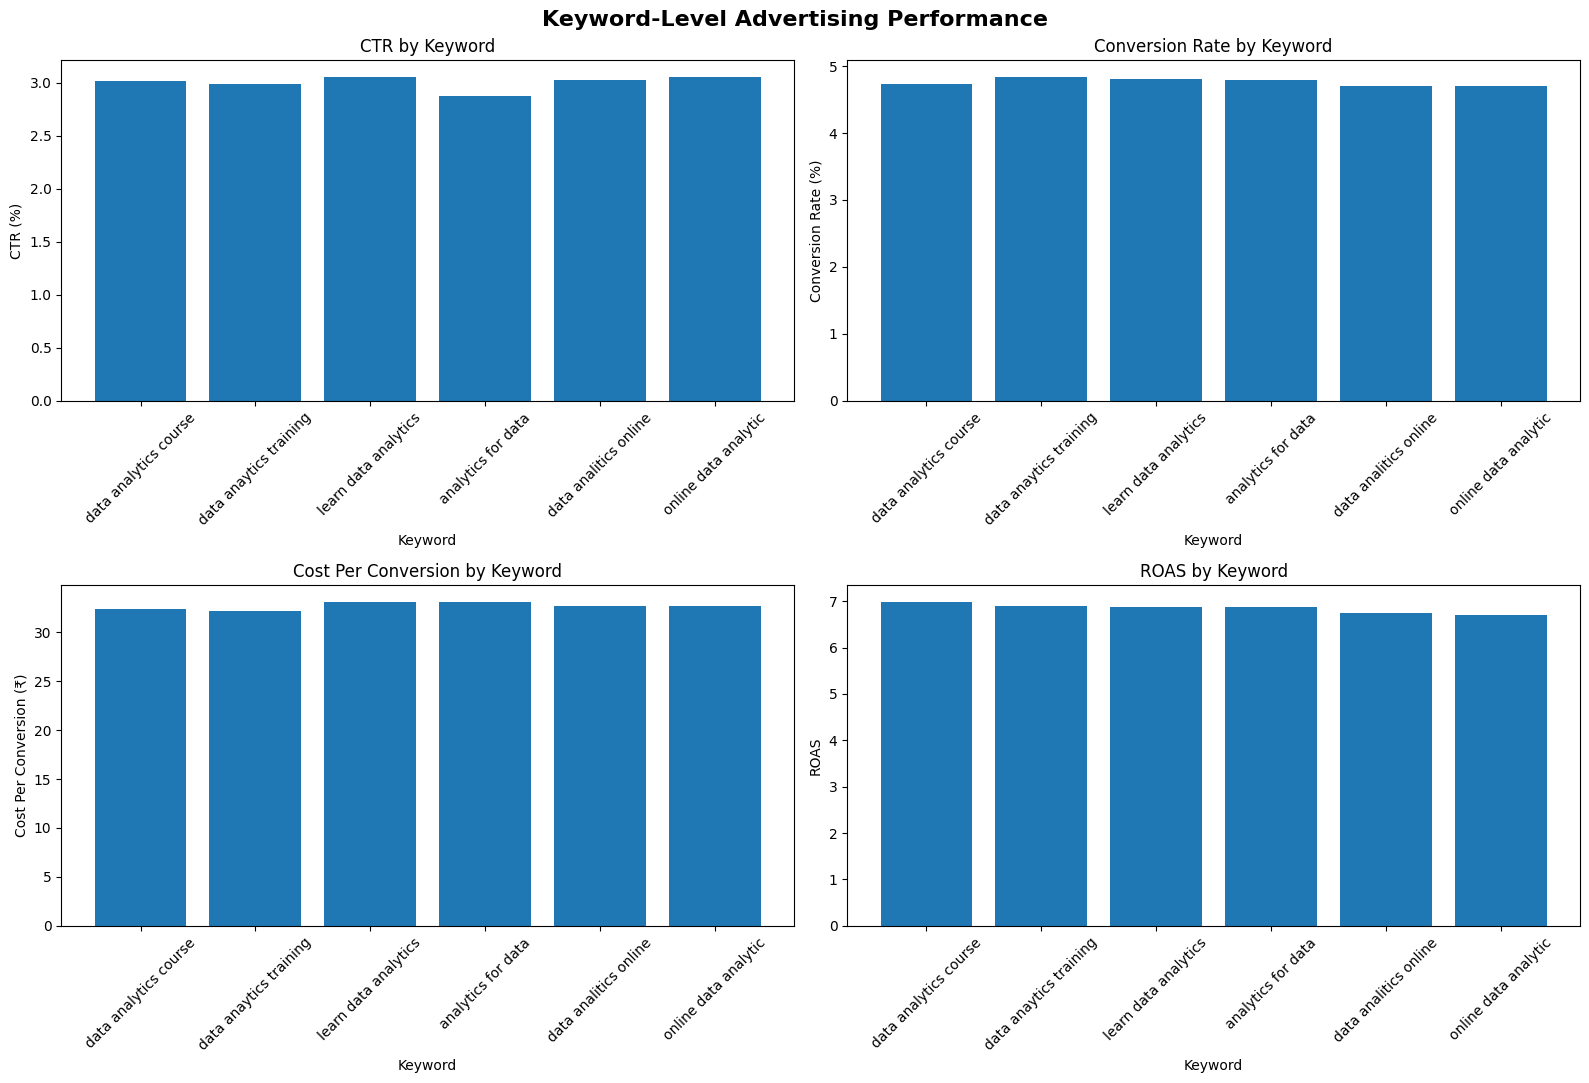

In [195]:
# Cell 92: Keyword Performance Visualization

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. CTR
axes[0, 0].bar(
    keyword_performance['Keyword'],
    keyword_performance['CTR (%)']
)
axes[0, 0].set_title('CTR by Keyword')
axes[0, 0].set_xlabel('Keyword')
axes[0, 0].set_ylabel('CTR (%)')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Conversion Rate
axes[0, 1].bar(
    keyword_performance['Keyword'],
    keyword_performance['Conversion Rate (%)']
)
axes[0, 1].set_title('Conversion Rate by Keyword')
axes[0, 1].set_xlabel('Keyword')
axes[0, 1].set_ylabel('Conversion Rate (%)')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Cost Per Conversion
axes[1, 0].bar(
    keyword_performance['Keyword'],
    keyword_performance['Cost Per Conversion']
)
axes[1, 0].set_title('Cost Per Conversion by Keyword')
axes[1, 0].set_xlabel('Keyword')
axes[1, 0].set_ylabel('Cost Per Conversion (₹)')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. ROAS
axes[1, 1].bar(
    keyword_performance['Keyword'],
    keyword_performance['ROAS']
)
axes[1, 1].set_title('ROAS by Keyword')
axes[1, 1].set_xlabel('Keyword')
axes[1, 1].set_ylabel('ROAS')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.suptitle(
    'Keyword-Level Advertising Performance',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()